# BPD screening: fine-tuning vs. training-free semantic search (VBRI). Complete experiment, A to Z

This notebook produces **every number, table and figure** of the paper in one run on one machine (Kaggle, Tesla T4):
data checks and data figures, fine-tuning of 7 encoders x 3 seeds with an honest training time, inference benchmark,
pooled dense and lexical retrieval baselines, VBRI, calibration, C-SSRS rule, ablation, k-sweep, statistics,
participant-level analysis, vignettes, all paper figures (PDF), LaTeX tables and `numbers.json`.

**Datasets** (attach the Kaggle dataset that contains both folders)
* `imbalance_free_dataset`: train 4,050 (1,350 per class, 150 per class per question), validation 333, test 333. **All models are trained on / store this set.**
* `augmented_dataset`: train 4,279 (unbalanced), same validation and test. Used **only** for the "unbalanced" rows of the ablation and to rebuild the 3,258 original answers for the data figures.
* Both are checked (row counts, labels, fingerprints) and the notebook stops if the main dataset is not the verified one.

**No test-set tuning.** k, temperature, margin and threshold are chosen on the validation set. The best fine-tuned model is chosen by validation macro-F1.

**Running it from VS Code with a Kaggle remote kernel**
1. On Kaggle, open a notebook session: Accelerator *GPU T4*, Internet *On*, Persistence *Files only* (or more), and attach the dataset.
2. In VS Code, open this notebook (it stays on your computer), select the Kaggle kernel, and press **Run All**. Compute and files live on Kaggle (`/kaggle/working/final_baseline_run`).
3. When it finishes, the last cell prints a results bundle into the notebook. **Save the notebook (Ctrl+S)** and run on your computer:
   `python experiments/publication_notebook/extract_bundle.py`. This copies all figures and tables into `VBRI_Publication_Paper/`.
   (Alternative: download `/kaggle/working/final_baseline_run_results.zip` and run the script with `--zip <file>`.)

**If the session or connection breaks:** reconnect and press **Run All** again. Finished training runs are skipped, an interrupted run resumes from its last checkpoint, and the training time stays correct (see section 3). Every later stage reads its inputs from disk, so it can also be re-run alone.

**Time:** about 1.5 h per seed for fine-tuning (3 seeds about 4 to 5 h), retrieval about 20 to 30 min, the rest a few minutes.

## 1. Setup, settings and environment
All switches are in the first cell. Leave `FORCE_FRESH = False` when you resume.

In [1]:
PROFILE = "kaggle"   # set by build_notebook.py: "kaggle" or "windows"

import os, sys, json, time, shutil, hashlib, platform, subprocess, random, math, gc, re, csv, statistics, zipfile, inspect, traceback, base64, io
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict

# Use ONE GPU so that timings are not affected by Kaggle's 2xT4 / DataParallel. Must be set before torch is imported.
os.environ["CUDA_VISIBLE_DEVICES"] = os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0]
os.environ["TOKENIZERS_PARALLELISM"] = "false"
if PROFILE == "windows":
    os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")   # Windows without developer mode cannot symlink the HF cache

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

for _mod, _pkg in [("contractions", "contractions"), ("rank_bm25", "rank-bm25"),
                   ("sentence_transformers", "sentence-transformers"), ("scipy", "scipy"), ("sklearn", "scikit-learn")]:
    try:
        __import__(_mod)
    except ImportError:
        _pip(_pkg)
import contractions

# ------------------------------ settings ------------------------------------
CODE_VERSION = "final_baseline_v1"
SEEDS = [42, 43, 44]                       # all models for seed 42 first, then 43, then 44
MODELS = ["ELECTRA", "BERT", "DistilBERT", "RoBERTa", "XLNet", "DeBERTa", "ModernBERT"]
MAX_EPOCHS = 15
PATIENCE = 2                               # early stopping on validation loss
TRAIN_SUBSET = None                        # None = full training set (only the local test mode uses a subset)
KEEP_WEIGHTS_SEEDS = [SEEDS[0]]            # weights are kept only for these seeds (needed for the inference benchmark)

# Stages. Every stage saves its results to disk, so any later stage can be re-run on its own after a restart.
RUN_DATA_FIGURES = True
RUN_SMOKE_TEST = True                      # short crash-and-resume check (skipped automatically once it has passed)
RUN_MAIN_TRAINING = True
RUN_INFERENCE_BENCH = True
RUN_RETRIEVAL = True                       # pooled baselines, lexical baselines, VBRI, calibration, ablation, k-sweep
RUN_VBRI_TIMING = True
RUN_ANALYSIS = True                        # statistics, patient level, vignettes, error analysis
RUN_FIGURES = True
RUN_TABLES = True
RUN_EXPORT = True
EMBED_BUNDLE_IN_NOTEBOOK = PROFILE == "kaggle"   # print the results bundle into the notebook (Kaggle remote kernel only)
COPY_TO_PAPER = PROFILE == "windows"       # copy final figures/tables straight into ../VBRI_Publication_Paper (if that folder exists)

# GPU use. "windows" = one big local GPU: every model trains with batch 16 in a single step (same effective batch 16
# as before, no gradient accumulation), larger evaluation and encoding batches, bf16 and TF32 on Ampere or newer.
FULL_BATCH = PROFILE == "windows"
EVAL_BS = 64 if PROFILE == "windows" else None   # None = the per-model value from the earlier baseline
ENCODE_BS = 256 if PROFILE == "windows" else 64

FORCE_FRESH = False                        # DANGER: True deletes everything this notebook produced. Leave False when resuming.
DATASET_DIR_OVERRIDE = None                # e.g. "/kaggle/input/<name>/imbalance_free_dataset"
AUG_DATASET_DIR_OVERRIDE = None            # e.g. "/kaggle/input/<name>/augmented_dataset"
N_BOOT = 10000                             # bootstrap resamples for confidence intervals

# Local test mode (tiny CPU run used to check the notebook before Kaggle). Never set this on Kaggle.
TEST_MODE = os.environ.get("BPD_TEST_MODE") == "1"
if TEST_MODE:
    SEEDS = [42]
    MODELS = ["DistilBERT"]
    MAX_EPOCHS = 2
    TRAIN_SUBSET = {"train": 160, "val": 333}
    KEEP_WEIGHTS_SEEDS = [42]
    N_BOOT = 300
    EMBED_BUNDLE_IN_NOTEBOOK = True
    print("!!! TEST MODE: tiny CPU run for checking the notebook. Results are NOT valid.")

ON_KAGGLE = Path("/kaggle/working").exists()
if PROFILE == "windows":
    # everything (checkpoints, results, figures) is saved next to this notebook
    WORK_DIR = Path(os.environ.get("BPD_WORK_DIR") or (Path.cwd() / "final_baseline_run_out"))
    PAPER_REPO_DIR = Path(os.environ.get("BPD_PAPER_DIR") or (Path.cwd().parent / "VBRI_Publication_Paper"))
else:
    WORK_DIR = Path(os.environ.get("BPD_WORK_DIR") or ("/kaggle/working/final_baseline_run" if ON_KAGGLE else "./final_baseline_run_out"))
    PAPER_REPO_DIR = None
if FORCE_FRESH and WORK_DIR.exists():
    print("!!! FORCE_FRESH=True -> deleting", WORK_DIR)
    shutil.rmtree(WORK_DIR)
RUNS_DIR = WORK_DIR / "runs"
RETR_DIR = WORK_DIR / "retrieval"
PAPER_DIR = WORK_DIR / "paper_assets"
FIG_DIR, TAB_DIR = PAPER_DIR / "figures", PAPER_DIR / "tables"
for _d in (WORK_DIR, RUNS_DIR, RETR_DIR, FIG_DIR, TAB_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("Work dir:", WORK_DIR.resolve())
print("Free disk (GB):", round(shutil.disk_usage(WORK_DIR).free / 1e9, 1), "(about 25 GB is needed for checkpoints, weights and model downloads)")
if PROFILE == "windows" and len(str(WORK_DIR.resolve())) > 120:
    print("!!! The work folder path is long. Windows limits paths to 260 characters; move the project closer to the drive root "
          "or enable long paths if you see 'file not found' errors when checkpoints are saved.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 6.0 MB/s eta 0:00:00
Work dir: /kaggle/working/final_baseline_run
Free disk (GB): 17.4 (about 25 GB is needed for checkpoints, weights and model downloads)


In [2]:
import torch, transformers, datasets
import numpy as np

# ModernBERT needs transformers >= 4.48. Upgrade if needed, then the kernel must be restarted once.
def _ver(v):
    return tuple(int(x) for x in re.findall(r"\d+", v)[:2])
if _ver(transformers.__version__) < (4, 48):
    _pip("transformers>=4.48", "accelerate")
    raise SystemExit("transformers was upgraded for ModernBERT. RESTART THE KERNEL, then run all cells again.")

cuda_ok = torch.cuda.is_available()
GPU_NAME = torch.cuda.get_device_name(0) if cuda_ok else "cpu"
CAP = torch.cuda.get_device_capability(0) if cuda_ok else (0, 0)
# T4 (compute capability 7.5) has no real bf16 -> fp16 for every model. bf16 only on Ampere+ (cc >= 8).
PRECISION = "bf16" if CAP[0] >= 8 else ("fp16" if cuda_ok else "fp32")

VRAM_TOTAL_GB = VRAM_FREE_GB = None
if PROFILE == "windows" and cuda_ok:
    # A PyTorch build without kernels for this GPU fails later with "no kernel image is available". Check it now.
    _arch = f"sm_{CAP[0]}{CAP[1]}"
    _archs = torch.cuda.get_arch_list()
    if _archs and _arch not in _archs and not any(a.startswith(f"sm_{CAP[0]}") for a in _archs):
        raise SystemExit(f"This PyTorch build ({torch.__version__}, archs {_archs}) has no kernels for {GPU_NAME} ({_arch}).\n"
                         "Install a CUDA 12.8+ build, e.g.:  pip install --upgrade torch --index-url https://download.pytorch.org/whl/cu128")
    _x = torch.randn(256, 256, device="cuda")
    (_x @ _x).sum().item()                                # fails here if the GPU cannot run kernels
    torch.backends.cuda.matmul.allow_tf32 = True           # faster fp32 matmuls on Ampere and newer (training itself uses bf16)
    torch.backends.cudnn.allow_tf32 = True
    _free, _total = torch.cuda.mem_get_info()
    VRAM_FREE_GB, VRAM_TOTAL_GB = round(_free / 1e9, 1), round(_total / 1e9, 1)
    print(f"GPU memory: {VRAM_FREE_GB} GB free of {VRAM_TOTAL_GB} GB")
    if VRAM_FREE_GB < 12:
        print("!!! Less than 12 GB of GPU memory is free. Close other programs that use the GPU (games, other notebooks, "
              "other training jobs) before training, or runs may crash with 'CUDA out of memory' and the times are not clean.")

ENV = {
    "code_version": CODE_VERSION, "started_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "gpu": GPU_NAME, "compute_capability": list(CAP), "precision": PRECISION,
    "visible_gpus": torch.cuda.device_count() if cuda_ok else 0,
    "torch": torch.__version__, "transformers": transformers.__version__, "datasets": datasets.__version__,
    "python": platform.python_version(), "cpu_count": os.cpu_count(), "platform": platform.platform(),
    "profile": PROFILE, "vram_total_gb": VRAM_TOTAL_GB, "vram_free_gb_at_start": VRAM_FREE_GB,
    "full_batch": FULL_BATCH, "eval_bs": EVAL_BS, "encode_bs": ENCODE_BS,
}
print(json.dumps(ENV, indent=2))
if not cuda_ok:
    print("\n!!! No GPU found. Training times will not be meaningful. "
          + ("Enable a GPU accelerator in Kaggle." if PROFILE == "kaggle" else "Install a CUDA build of PyTorch (see the first markdown cell)."))
elif PROFILE == "kaggle" and "T4" not in GPU_NAME:
    print(f"\n!!! GPU is '{GPU_NAME}', not a Tesla T4. Times are only comparable with other runs on the same GPU type.")
elif PROFILE == "windows":
    print(f"\nAll times in this run are measured on: {GPU_NAME} (report this GPU in the paper).")
(WORK_DIR / "env.json").write_text(json.dumps(ENV, indent=2), encoding="utf-8")

{
  "code_version": "final_baseline_v1",
  "started_utc": "2026-11-27T08:38:42+00:00",
  "gpu": "Tesla T4",
  "compute_capability": [
    7,
    5
  ],
  "precision": "fp16",
  "visible_gpus": 1,
  "torch": "2.10.0+cu128",
  "transformers": "5.0.0",
  "datasets": "4.8.3",
  "python": "3.12.12",
  "cpu_count": 4,
  "platform": "Linux-6.18.55+-x86_64-with-glibc2.35",
  "profile": "kaggle",
  "vram_total_gb": null,
  "vram_free_gb_at_start": null,
  "full_batch": false,
  "eval_bs": null,
  "encode_bs": 64
}


510

## 2. Helpers: JSON, metrics, statistics and figure style
Metrics are computed with one function (`summarize`) for every model, so all numbers are comparable.

In [3]:
def utc_now():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")

def atomic_write_json(path, obj):
    """Write JSON so that a crash can never leave a half-written file."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)
        f.flush()
        os.fsync(f.fileno())
    for attempt in range(10):                 # Windows: antivirus / indexer can hold the target for a moment
        try:
            os.replace(tmp, path)
            return
        except PermissionError:
            time.sleep(0.2 * (attempt + 1))
    os.replace(tmp, path)

def read_json(path, default=None):
    try:
        with open(path, encoding="utf-8") as f:
            return json.load(f)
    except Exception:
        return default

CLASSES = ["Normal", "BPD", "Inconclusive"]

def confusion(y, p, k=3):
    cm = [[0] * k for _ in range(k)]
    for a, b in zip(y, p):
        cm[int(a)][int(b)] += 1
    return cm

def summarize(y, p):
    """All metrics in %, computed from labels y and predictions p (0=Normal, 1=BPD, 2=Inconclusive)."""
    cm = confusion(y, p)
    n = len(y)
    per = []
    for c in range(3):
        tp = cm[c][c]
        fp = sum(cm[i][c] for i in range(3)) - tp
        fn = sum(cm[c]) - tp
        pr = tp / (tp + fp) if tp + fp else 0.0
        rc = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * pr * rc / (pr + rc) if pr + rc else 0.0
        per.append((pr, rc, f1, sum(cm[c])))
    tp = cm[1][1]; fn = sum(cm[1]) - tp
    fp = sum(cm[i][1] for i in (0, 2)); tn = n - tp - fn - fp
    safe = lambda a, b: 100.0 * a / b if b else 0.0
    return {
        "n": n, "confusion": cm,
        "accuracy": 100.0 * sum(cm[i][i] for i in range(3)) / n,
        "macro_f1": 100.0 * sum(x[2] for x in per) / 3,
        "weighted_f1": 100.0 * sum(x[2] * x[3] for x in per) / n,
        "bpd_f1": 100.0 * per[1][2], "bpd_precision": 100.0 * per[1][0],
        "bpd_sensitivity": 100.0 * per[1][1], "inconclusive_recall": 100.0 * per[2][1],
        "bin_sensitivity": safe(tp, tp + fn), "bin_specificity": safe(tn, tn + fp),
        "bin_ppv": safe(tp, tp + fp), "bin_npv": safe(tn, tn + fn),
        "bin_accuracy": safe(tp + tn, n),
        "bin_dor": (tp * tn) / (fp * fn) if fp * fn else float("nan"),
    }

def auroc(scores, ybin):
    """AUROC by the rank (Mann-Whitney) method, ties get average rank."""
    n = len(scores)
    n_pos = sum(1 for y in ybin if y); n_neg = n - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    order = sorted(range(n), key=lambda i: scores[i])
    ranks = [0.0] * n
    i = 0
    while i < n:
        j = i
        while j + 1 < n and scores[order[j + 1]] == scores[order[i]]:
            j += 1
        avg = (i + j) / 2 + 1
        for t in range(i, j + 1):
            ranks[order[t]] = avg
        i = j + 1
    r_pos = sum(ranks[i] for i in range(n) if ybin[i])
    return (r_pos - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def spec_at_sens(scores, ybin, target=0.85):
    """Specificity at the highest threshold whose sensitivity reaches `target`."""
    P = sum(1 for y in ybin if y); N = len(ybin) - P
    if P == 0 or N == 0:
        return float("nan"), None
    for t in sorted(set(scores), reverse=True):
        tp = sum(1 for s, y in zip(scores, ybin) if s >= t and y)
        fp = sum(1 for s, y in zip(scores, ybin) if s >= t and not y)
        if tp / P >= target:
            return 100.0 * (1 - fp / N), t
    return 0.0, None

def fingerprint(rows, keys=("question_id", "label", "answer")):
    lines = sorted("|".join(str(r[k]).strip() for k in keys) for r in rows)
    return hashlib.sha256("\n".join(lines).encode("utf-8")).hexdigest()

def pct_stats(vals):
    vals = [v for v in vals if v is not None and not (isinstance(v, float) and math.isnan(v))]
    if not vals:
        return float("nan"), float("nan")
    return statistics.mean(vals), (statistics.stdev(vals) if len(vals) > 1 else 0.0)

# ------------------------------ statistics ----------------------------------
def mcnemar(correct_a, correct_b):
    """McNemar test on paired correctness. b = A wrong & B right, c = A right & B wrong."""
    b = sum(1 for a, bb in zip(correct_a, correct_b) if not a and bb)
    c = sum(1 for a, bb in zip(correct_a, correct_b) if a and not bb)
    n = b + c
    if n == 0:
        return {"b": b, "c": c, "chi2": 0.0, "p_asymptotic": 1.0, "p_exact": 1.0}
    chi2 = (abs(b - c) - 1.0) ** 2 / n                     # with continuity correction
    p_asym = math.erfc(math.sqrt(chi2 / 2.0))
    p_exact = min(1.0, 2.0 * sum(math.comb(n, k) for k in range(min(b, c) + 1)) / 2 ** n)
    return {"b": b, "c": c, "chi2": chi2, "p_asymptotic": p_asym, "p_exact": p_exact}

def bootstrap_ci(y, preds_by_name, metric_keys, n_boot=None, seed=0, diffs=()):
    """Paired percentile bootstrap (95%) over test answers.
    preds_by_name: {name: list of predictions}; diffs: pairs (a, b) for which a-b is also resampled."""
    import numpy as _np
    n_boot = n_boot or N_BOOT
    rng = _np.random.default_rng(seed)
    y = _np.asarray(y)
    P = {k: _np.asarray(v) for k, v in preds_by_name.items()}
    draws = {(name, m): [] for name in P for m in metric_keys}
    ddraws = {(a, b, m): [] for a, b in diffs for m in metric_keys}
    for _ in range(n_boot):
        ix = rng.integers(0, len(y), len(y))
        yy = y[ix].tolist()
        cur = {name: summarize(yy, p[ix].tolist()) for name, p in P.items()}
        for name in P:
            for m in metric_keys:
                draws[(name, m)].append(cur[name][m])
        for a, b in diffs:
            for m in metric_keys:
                ddraws[(a, b, m)].append(cur[a][m] - cur[b][m])
    q = lambda v: (float(_np.percentile(v, 2.5)), float(_np.percentile(v, 97.5)))
    out = {name: {m: {"point": summarize(y.tolist(), P[name].tolist())[m], "ci95": q(draws[(name, m)])} for m in metric_keys} for name in P}
    dout = {f"{a} - {b}": {m: {"point": out[a][m]["point"] - out[b][m]["point"], "ci95": q(ddraws[(a, b, m)]),
                               "p_two_sided": float(min(1.0, 2 * min(_np.mean(_np.asarray(ddraws[(a, b, m)]) <= 0),
                                                                    _np.mean(_np.asarray(ddraws[(a, b, m)]) >= 0))))}
                            for m in metric_keys} for a, b in diffs}
    return out, dout


# ------------------------------ figure style --------------------------------
import matplotlib
if not hasattr(sys, "ps1") and "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

C_FT, C_VB, C_BASE, C_LEX = "#2a78d6", "#eb6834", "#9a9893", "#c9c7c1"   # fine-tuned, VBRI, dense baseline, lexical
INK, INK2, GRID = "#1f1f1e", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
    "savefig.bbox": "tight", "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def save_fig(fig, name):
    """Save a figure as PDF (for LaTeX) and PNG, show it inline, then close it."""
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png")
    try:
        plt.show()
    except Exception:
        pass
    plt.close(fig)
    print("  figure saved:", name)

def draw_cm(ax, cm, title, cmap="Blues"):
    cm = np.asarray(cm)
    rs = cm.sum(1, keepdims=True)
    norm = np.divide(cm, rs, out=np.zeros_like(cm, dtype=float), where=rs != 0)
    ax.imshow(norm, cmap=cmap, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n{norm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if norm[i, j] > 0.55 else INK)
    acc = np.trace(cm) / max(cm.sum(), 1) * 100
    ax.set_title(f"{title}\nacc. {acc:.1f}%, BPD recall {norm[1, 1] * 100:.1f}%", fontsize=9)
    ax.set_xticks(range(3), CLASSES, rotation=20)
    ax.set_yticks(range(3), CLASSES)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

## 3. Resume-safe timer

`RunTimer` is a Trainer callback. It keeps the numbers that matter in files on disk, so they survive a Kaggle restart:

| file | content |
|---|---|
| `ledger.json` | one entry per session: start time, GPU, active seconds (heartbeat every 20 s), status (`running`, `interrupted`, `crashed`, `completed`) and a summary |
| `checkpoint-N/timing_at_checkpoint.json` | cumulative effective training time at the moment checkpoint N was saved |
| `train_complete.json` | written when training finished normally |

Definitions: **effective** = time stored in the checkpoint we resumed from + active time after the resume. **gross** = sum of the active time of all sessions. **wasted** = gross - effective (the partial epoch lost in a crash). Evaluation and checkpoint-saving time are part of training time (as in Hugging Face's own `train_runtime`) and are also reported separately.

In [4]:
try:
    from transformers import TrainerCallback
except Exception:                      # lets the timing logic be unit-tested without transformers
    class TrainerCallback:
        pass


class RunTimer(TrainerCallback):
    """Active-training-time bookkeeping that survives crashes and resumes."""

    def __init__(self, run_dir, base=None, resumed_from_step=0, meta=None, heartbeat_s=20.0):
        self.run_dir = Path(run_dir)
        self.ledger_path = self.run_dir / "ledger.json"
        base = base or {}
        self.base_effective = float(base.get("effective_s", 0.0))
        self.base_eval = float(base.get("eval_s", 0.0))
        self.base_save = float(base.get("save_s", 0.0))
        self.resumed_from_step = int(resumed_from_step)
        self.meta = dict(meta or {})
        self.heartbeat_s = float(heartbeat_s)
        self.eval_s = 0.0            # evaluation time in this session
        self.save_s = 0.0            # checkpoint-saving time in this session
        self._t0 = None
        self._frozen = None
        self._last_hb = 0.0
        self._open = False
        self._ledger = None

    # ---- accessors
    def active_s(self):
        if self._t0 is None:
            return 0.0
        return self._frozen if self._frozen is not None else time.perf_counter() - self._t0

    def effective_s(self):
        return self.base_effective + self.active_s()

    def eval_total_s(self):
        return self.base_eval + self.eval_s

    def save_total_s(self):
        return self.base_save + self.save_s

    # ---- ledger
    def _load_ledger(self):
        led = read_json(self.ledger_path, None)
        if not isinstance(led, dict) or "sessions" not in led:
            led = {"code_version": CODE_VERSION, "created_utc": utc_now(), "sessions": []}
        return led

    def _heartbeat(self, status=None, step=None, epoch=None):
        s = self._ledger["sessions"][-1]
        s["active_s"] = round(self.active_s(), 3)
        s["effective_s_so_far"] = round(self.effective_s(), 3)
        s["last_heartbeat_utc"] = utc_now()
        if step is not None:
            s["last_step"] = int(step)
        if epoch is not None:
            s["last_epoch"] = float(epoch)
        if status:
            s["status"] = status
        atomic_write_json(self.ledger_path, self._ledger)
        self._last_hb = time.perf_counter()

    @staticmethod
    def summarize_ledger(led, effective_s, eval_s, save_s):
        gross = sum(float(s.get("active_s", 0.0)) for s in led["sessions"])
        return {
            "effective_s": round(effective_s, 3), "eval_s": round(eval_s, 3), "save_s": round(save_s, 3),
            "gross_s": round(gross, 3), "wasted_s": round(max(0.0, gross - effective_s), 3),
            "n_sessions": len(led["sessions"]),
            "resumed": any(s.get("resumed_from_step", 0) > 0 for s in led["sessions"]),
            "session_status": [s.get("status") for s in led["sessions"]],
        }

    def close(self, status, step=None, epoch=None):
        """Finish this session (status: completed / crashed). Safe to call twice."""
        if not self._open:
            return
        self._frozen = time.perf_counter() - self._t0
        self._heartbeat(status=status, step=step, epoch=epoch)
        self._ledger["summary"] = self.summarize_ledger(
            self._ledger, self.effective_s(), self.eval_total_s(), self.save_total_s())
        atomic_write_json(self.ledger_path, self._ledger)
        self._open = False
        if status == "completed":
            atomic_write_json(self.run_dir / "train_complete.json",
                              {"finished_utc": utc_now(), **self._ledger["summary"]})

    # ---- Trainer callback hooks
    def on_train_begin(self, args, state, control, **kwargs):
        led = self._load_ledger()
        for s in led["sessions"]:                      # a session still marked running was killed
            if s.get("status") == "running":
                s["status"] = "interrupted"
        led.pop("summary", None)
        self._t0 = time.perf_counter()
        self._frozen = None
        led["sessions"].append({
            "session": len(led["sessions"]) + 1, "started_utc": utc_now(),
            "resumed_from_step": self.resumed_from_step,
            "base_effective_s": round(self.base_effective, 3),
            "active_s": 0.0, "status": "running", **self.meta,
        })
        self._ledger = led
        self._open = True
        self._heartbeat()
        return control

    def on_step_end(self, args, state, control, **kwargs):
        if self._open and time.perf_counter() - self._last_hb >= self.heartbeat_s:
            self._heartbeat(step=state.global_step, epoch=state.epoch)
        return control

    def on_epoch_end(self, args, state, control, **kwargs):
        if self._open:
            self._heartbeat(step=state.global_step, epoch=state.epoch)
        return control

    def on_save(self, args, state, control, **kwargs):
        if not self._open:
            return control
        ck = Path(args.output_dir) / f"checkpoint-{state.global_step}"
        if ck.exists():
            atomic_write_json(ck / "timing_at_checkpoint.json", {
                "global_step": int(state.global_step), "epoch": float(state.epoch or 0.0),
                "effective_s": round(self.effective_s(), 3),
                "eval_s": round(self.eval_total_s(), 3), "save_s": round(self.save_total_s(), 3),
                "written_utc": utc_now(), "session": len(self._ledger["sessions"]),
            })
        self._heartbeat(step=state.global_step, epoch=state.epoch)
        return control

    def on_train_end(self, args, state, control, **kwargs):
        self.close("completed", step=state.global_step, epoch=state.epoch)
        return control


# ---------------------------- checkpoint helpers ------------------------------
def list_checkpoints(run_dir):
    cks = [p for p in Path(run_dir).glob("checkpoint-*") if p.is_dir() and p.name.split("-")[-1].isdigit()]
    return sorted(cks, key=lambda p: int(p.name.split("-")[-1]), reverse=True)

def checkpoint_ok(ck):
    """A checkpoint is usable only if weights, trainer state and OUR timing file are all present and readable."""
    ck = Path(ck)
    has_weights = any((ck / n).exists() for n in
                      ("model.safetensors", "pytorch_model.bin", "model.safetensors.index.json", "pytorch_model.bin.index.json"))
    st = read_json(ck / "trainer_state.json", None)
    tm = read_json(ck / "timing_at_checkpoint.json", None)
    return bool(has_weights and isinstance(st, dict) and isinstance(tm, dict) and "effective_s" in tm)

def pick_resume_checkpoint(run_dir, log=print):
    """Latest valid checkpoint (and its timing). Invalid newer ones (e.g. half-written when Kaggle died) are deleted."""
    for ck in list_checkpoints(run_dir):
        if checkpoint_ok(ck):
            return ck, read_json(ck / "timing_at_checkpoint.json")
        log(f"  [resume] checkpoint {ck.name} is incomplete or has no timing file -> deleting it")
        shutil.rmtree(ck, ignore_errors=True)
    return None, None

## 4. Datasets and their checks

In [5]:
from datasets import load_from_disk, Dataset, DatasetDict

EXPECTED = {   # imbalance_free_dataset (main dataset: fine-tuning AND VBRI use this training set)
    "train_rows": 4050, "val_rows": 333, "test_rows": 333,
    "train_per_class": 1350, "test_label_counts": {0: 225, 1: 67, 2: 41},
    "train_fp": "529c5eab3547f1e7f7c4240444adcd6296c377d141ac6e275b488e066e1b477f",
    "test_fp": "b0d1f78b4093c5ef95ad488a014ddf09c5c161e4953f786e79341c7085578941",
}
EXPECTED_AUG = {"train_rows": 4279, "label_counts": {0: 1746, 1: 1612, 2: 921}}     # augmented_dataset (ablation only)
EXPECTED_ORIG = {                                                                    # the 3,258 original answers
    "rows": 3258, "participants": 362, "class_counts": {0: 2195, 1: 673, 2: 390},
    "orig_train_counts": {0: 1746, 1: 538, 2: 308},
    "per_question": {1: (198, 118, 46), 2: (244, 71, 47), 3: (283, 51, 28), 4: (240, 33, 89), 5: (325, 22, 15),
                     6: (230, 99, 33), 7: (227, 90, 45), 8: (220, 113, 29), 9: (228, 76, 58)},
}
DSM5 = {1: "Abandonment avoidance", 2: "Unstable relationships", 3: "Identity disturbance", 4: "Impulsive behaviours",
        5: "Suicidal / self-harm", 6: "Affective instability", 7: "Chronic emptiness", 8: "Inappropriate anger",
        9: "Paranoia / dissociation"}

def find_dataset_dirs(name, override=None):
    if override:
        return [Path(override)]
    found = []
    for root in [Path("/kaggle/input"), Path("."), Path("experiments/dataset"), Path("../experiments/dataset"), Path("./dataset")]:
        if not root.exists():
            continue
        for dirpath, dirnames, _ in os.walk(root):
            d = Path(dirpath)
            if len(d.relative_to(root).parts) > 5:
                dirnames[:] = []
                continue
            if d.name == name and (d / "dataset_dict.json").exists():
                found.append(d.resolve())
                dirnames[:] = []
    return list(dict.fromkeys(found))

def rows_of(ds):
    return ds.to_pandas().to_dict("records")

# ------------------------------ main dataset ---------------------------------
_c = find_dataset_dirs("imbalance_free_dataset", DATASET_DIR_OVERRIDE)
if not _c:
    raise FileNotFoundError("imbalance_free_dataset not found. Attach the Kaggle dataset or set DATASET_DIR_OVERRIDE.")
DATA_DIR = _c[0]
print("Candidates:", [str(p) for p in _c])
print("USING MAIN DATASET :", DATA_DIR)
RAW = load_from_disk(str(DATA_DIR))
assert len(RAW["train"]) == EXPECTED["train_rows"], f"train rows {len(RAW['train'])} != {EXPECTED['train_rows']}"
assert len(RAW["validation"]) == EXPECTED["val_rows"] and len(RAW["test"]) == EXPECTED["test_rows"], "val/test size mismatch"
tr_rows, va_rows, te_rows = rows_of(RAW["train"]), rows_of(RAW["validation"]), rows_of(RAW["test"])
tr_counts = Counter(int(r["label"]) for r in tr_rows)
assert all(tr_counts[c] == EXPECTED["train_per_class"] for c in (0, 1, 2)), f"train not balanced: {tr_counts}"
q_counts = Counter((int(r["question_id"]), int(r["label"])) for r in tr_rows)
assert all(v == 150 for v in q_counts.values()) and len(q_counts) == 27, "train is not 150 per class per question"
assert dict(Counter(int(r["label"]) for r in te_rows)) == EXPECTED["test_label_counts"], "test label counts differ"
fp_tr, fp_va, fp_te = fingerprint(tr_rows), fingerprint(va_rows), fingerprint(te_rows)
assert fp_tr == EXPECTED["train_fp"], "TRAIN fingerprint differs from the verified imbalance_free_dataset"
assert fp_te == EXPECTED["test_fp"], "TEST fingerprint differs: the test set is not the one used for VBRI"
print("OK: train 4050 (1350/class, 150/class/question), validation 333, test 333 (225/67/41). Fingerprints match.")

# ------------------------------ augmented dataset (ablation + data figures) --
AUG_OK, RAW_AUG = False, None
_a = find_dataset_dirs("augmented_dataset", AUG_DATASET_DIR_OVERRIDE)
if _a:
    print("USING AUGMENTED DATASET (ablation only):", _a[0])
    RAW_AUG = load_from_disk(str(_a[0]))
    aug_tr = rows_of(RAW_AUG["train"])
    same_eval = fingerprint(rows_of(RAW_AUG["validation"])) == fp_va and fingerprint(rows_of(RAW_AUG["test"])) == fp_te
    if not same_eval:
        print("!!! augmented_dataset has a different validation/test split -> not used")
    else:
        AUG_OK = True
        ac = dict(sorted(Counter(int(r["label"]) for r in aug_tr).items()))
        if len(aug_tr) != EXPECTED_AUG["train_rows"] or ac != EXPECTED_AUG["label_counts"]:
            print(f"!!! augmented_dataset train is {len(aug_tr)} rows {ac}; expected {EXPECTED_AUG}. Used, but check it.")
        else:
            print("OK: augmented_dataset train 4279 (1746/1612/921), same validation and test split.")
else:
    print("!!! augmented_dataset not found: the 'unbalanced' ablation rows and the original-data figures will be skipped.")

# ------------------------------ the 3,258 original answers -------------------
def _is_original(r):
    m = r.get("augmentation_method")
    return m is None or (isinstance(m, float) and math.isnan(m)) or str(m).strip().lower() in ("", "original", "none", "nan")

ORIG_OK, ORIG_ROWS = False, None
if AUG_OK:
    orig_train = [r for r in aug_tr if _is_original(r)]
    ORIG_ROWS = orig_train + va_rows + te_rows
    oc = dict(sorted(Counter(int(r["label"]) for r in ORIG_ROWS).items()))
    otc = dict(sorted(Counter(int(r["label"]) for r in orig_train).items()))
    oq = {q: tuple(sum(1 for r in ORIG_ROWS if int(r["question_id"]) == q and int(r["label"]) == c) for c in (0, 1, 2)) for q in range(1, 10)}
    n_part = len({int(r["participant_id"]) for r in ORIG_ROWS})
    checks = {"rows": len(ORIG_ROWS) == EXPECTED_ORIG["rows"], "classes": oc == EXPECTED_ORIG["class_counts"],
              "train": otc == EXPECTED_ORIG["orig_train_counts"], "per_question": oq == EXPECTED_ORIG["per_question"],
              "participants": n_part == EXPECTED_ORIG["participants"]}
    ORIG_OK = all(checks.values())
    print("Original 3,258 answers rebuilt:" if ORIG_OK else "!!! original data check FAILED:", checks, oc)

DATASET_REPORT = {"path": str(DATA_DIR), "aug_path": str(_a[0]) if _a else None, "aug_ok": AUG_OK, "orig_ok": ORIG_OK,
                  "train_fp": fp_tr, "val_fp": fp_va, "test_fp": fp_te,
                  "train": len(RAW["train"]), "validation": len(RAW["validation"]), "test": len(RAW["test"])}
atomic_write_json(WORK_DIR / "dataset_used.json", DATASET_REPORT)

# keep test info aligned with prediction order
TEST_IDS = [int(r["id"]) for r in te_rows]
TEST_QIDS = [int(r["question_id"]) for r in te_rows]
TEST_Y = [int(r["label"]) for r in te_rows]
TEST_PIDS = [int(r["participant_id"]) for r in te_rows]
TEST_ANS_RAW = [str(r["answer"]).strip() for r in te_rows]

Candidates: ['/kaggle/input/datasets/mehedihasanmoon/imbalance-free-dataset/imbalance_free_dataset']
USING MAIN DATASET : /kaggle/input/datasets/mehedihasanmoon/imbalance-free-dataset/imbalance_free_dataset
OK: train 4050 (1350/class, 150/class/question), validation 333, test 333 (225/67/41). Fingerprints match.
USING AUGMENTED DATASET (ablation only): /kaggle/input/datasets/shadmanshafeen141/bpd-qna-classification-dataset-augmented/augmented_dataset
OK: augmented_dataset train 4279 (1746/1612/921), same validation and test split.
Original 3,258 answers rebuilt: {'rows': True, 'classes': True, 'train': True, 'per_question': True, 'participants': True} {0: 2195, 1: 673, 2: 390}


Text cleaning for the fine-tuned models: the same `TextNormalizer` as the earlier baseline notebook (lower case, special characters, contractions, slang). Retrieval uses the raw answer text, as in the original VBRI experiments.

In [6]:
class TextNormalizer:
    def __init__(self):
        # Initialize text normalization dictionary
        self.slang_dict = {
            'imo': 'in my opinion',
            'imho': 'in my humble opinion',
            'tbh': 'to be honest',
            'afaik': 'as far as i know',
            'idk': "i don't know",
            'smh': 'shaking my head',
            'btw': 'by the way',
            'asap': 'as soon as possible',
            'fyi': 'for your information',
            'np': 'no problem',
            'thx': 'thanks',
            'pls': 'please',
            'u': 'you',
            'r': 'are',
            'ur': 'your',
            'n': 'and',
            'b/c': 'because',
            'cz' : 'because',
            'bcz' : 'because',
            'ofc' : 'ofcourse',
            'govt': 'government',
            'dept': 'department',
            'est': 'established',
            'approx': 'approximately',
            'min': 'minimum',
            'max': 'maximum',
            "n't": 'not',
            "nt" : 'not',
            "gn" : 'good night',
            "f9" : 'fine',
            'bpd': 'borderline personality disorder',
            'dbt': 'dialectical behavior therapy',
            'fp': 'favorite person',
            'si': 'suicidal ideation',
            'sh': 'self harm',
            "its" : 'it is',
            "people's" : 'people',
            "sha'n't": "shall not",
            "shan't've": "shall not have",
            "she'd": "she had / she would",
            "she'd've": "she would have",
            "she'll": "she shall / she will",
            "she'll've": "she shall have / she will have",
            "she's": "she has / she is",
            "should've": "should have",
            "shouldn't": "should not",
            "shouldn't've": "should not have",
            "so've": "so have",
            "so's": "so as / so is",
            "that'd": "that would / that had",
            "that'd've": "that would have",
            "that's": "that has / that is",
            "there'd": "there had / there would",
            "there'd've": "there would have",
            "there's": "there has / there is",
            "they'd": "they had / they would",
            "they'd've": "they would have",
            "they'll": "they shall / they will",
            "they'll've": "they shall have / they will have",
            "they're": "they are",
            "they've": "they have",
            "to've": "to have",
            "wasn't": "was not",
            "we'd": "we had / we would",
            "we'd've": "we would have",
            "we'll": "we will",
            "we'll've": "we will have",
            "we're": "we are",
            "we've": "we have",
            "weren't": "were not",
            "what'll": "what shall / what will",
            "what'll've": "what shall have / what will have",
            "what're": "what are",
            "what's": "what has / what is",
            "what've": "what have",
            "when's": "when has / when is",
            "when've": "when have",
            "where'd": "where did",
            "where's": "where has / where is",
            "where've": "where have",
            "who'll": "who shall / who will",
            "who'll've": "who shall have / who will have",
            "who's": "who has / who is",
            "who've": "who have",
            "why's": "why has / why is",
            "why've": "why have",
            "will've": "will have",
            "won't": "will not",
            "won't've": "will not have",
            "would've": "would have",
            "wouldn't": "would not",
            "wouldn't've": "would not have",
            "y'all": "you all",
            "y'all'd": "you all would",
            "y'all'd've": "you all would have",
            "y'all're": "you all are",
            "y'all've": "you all have",
            "you'd": "you had / you would",
            "you'd've": "you would have",
            "you'll": "you shall / you will",
            "you'll've": "you shall have / you will have",
            "you're": "you are",
            "you've": "you have"
}

    def clean_text(self, text):
        """Basic text cleaning"""
        text = str(text).lower().strip()
        # Remove special characters (keep basic punctuation)
        text = re.sub(r"[^a-zA-Z0-9\s.,!?']", "", text)
        return text

    def expand_slang(self, text):
        """Replace slang terms using dictionary"""
        words = text.split()
        expanded_words = [self.slang_dict.get(word, word) for word in words]
        return ' '.join(expanded_words)

    def normalize_text(self, text):
        """Full text normalization pipeline"""
        if not isinstance(text, str) or not text.strip():
            return text
            
        # Clean text first
        text = self.clean_text(text)
        # Fix contractions
        text = contractions.fix(text)
        # Expand slang
        text = self.expand_slang(text)
        return text


# ---- same text cleaning as the earlier baseline (lower-case, special characters, contractions, slang) ----
normalizer = TextNormalizer()
def _normalise_split(ds):
    df = ds.to_pandas()
    for col in ("question", "answer"):
        df[col] = df[col].apply(normalizer.normalize_text)
    return Dataset.from_pandas(df, preserve_index=False)

CLEAN = DatasetDict({s: _normalise_split(RAW[s]) for s in ("train", "validation", "test")})
TEST_Q_NORM, TEST_A_NORM = list(CLEAN["test"]["question"]), list(CLEAN["test"]["answer"])
print("Example (normalised):", CLEAN["train"][0]["answer"][:120])

Example (normalised): how does playing games affect my studies?


## 5. Data figures
Figure: class distribution and label mix per question (original 3,258 answers). Figure: the training views and how much of the balanced set is augmented text.

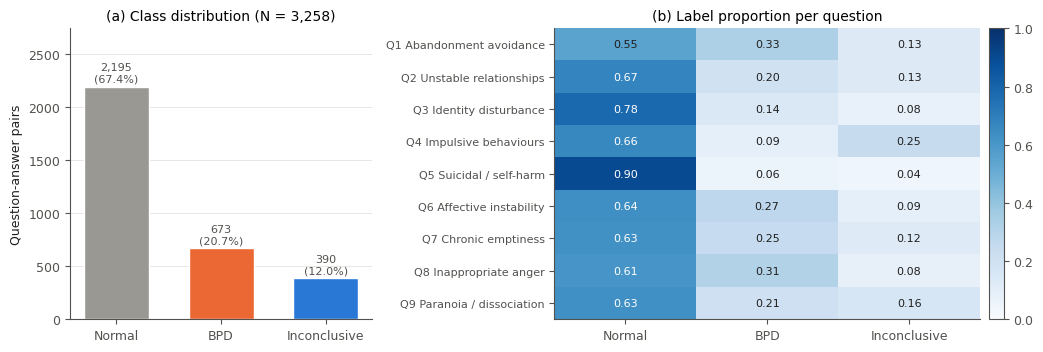

  figure saved: fig_data_overview


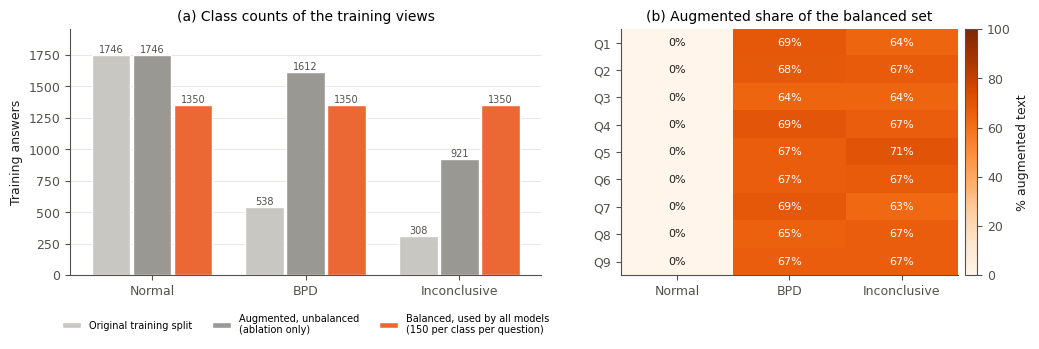

  figure saved: fig_training_views
{
 "original": {
  "rows": 3258,
  "class_counts": {
   "Normal": 2195,
   "BPD": 673,
   "Inconclusive": 390
  },
  "question_label_proportions": {
   "Q1": {
    "Normal": 0.547,
    "BPD": 0.326,
    "Inconclusive": 0.1271
   },
   "Q2": {
    "Normal": 0.674,
    "BPD": 0.1961,
    "Inconclusive": 0.1298
   },
   "Q3": {
    "Normal": 0.7818,
    "BPD": 0.1409,
    "Inconclusive": 0.0773
   },
   "Q4": {
    "Normal": 0.663,
    "BPD": 0.0912,
    "Inconclusive": 0.2459
   },
   "Q5": {
    "Normal": 0.8978,
    "BPD": 0.0608,
    "Inconclusive": 0.0414
   },
   "Q6": {
    "Normal": 0.6354,
    "BPD": 0.2735,
    "Inconclusive": 0.0912
   },
   "Q7": {
    "Normal": 0.6271,
    "BPD": 0.2486,
    "Inconclusive": 0.1243
   },
   "Q8": {
    "Normal": 0.6077,
    "BPD": 0.3122,
    "Inconclusive": 0.0801
   },
   "Q9": {
    "Normal": 0.6298,
    "BPD": 0.2099,
    "Inconclusive": 0.1602
   }
  },
  "mean_words": {
   "Normal": 21.10250569476082,
 

In [7]:
def make_data_figures():
    stats = {}
    # ---- Figure: dataset overview (original 3,258 answers) ----
    if ORIG_OK:
        oc = Counter(int(r["label"]) for r in ORIG_ROWS)
        n = len(ORIG_ROWS)
        props = np.array([[sum(1 for r in ORIG_ROWS if int(r["question_id"]) == q and int(r["label"]) == c) for c in (0, 1, 2)]
                          for q in range(1, 10)], dtype=float)
        props = props / props.sum(1, keepdims=True)
        lens = {c: [len(str(r["answer"]).split()) for r in ORIG_ROWS if int(r["label"]) == c] for c in (0, 1, 2)}
        stats["original"] = {"rows": n, "class_counts": {CLASSES[c]: oc[c] for c in (0, 1, 2)},
                             "question_label_proportions": {f"Q{q}": dict(zip(CLASSES, props[q - 1].round(4).tolist())) for q in range(1, 10)},
                             "mean_words": {CLASSES[c]: float(np.mean(lens[c])) for c in (0, 1, 2)}}
        fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1, 1.5]})
        ax = axes[0]
        vals = [oc[c] for c in (0, 1, 2)]
        bars = ax.bar(CLASSES, vals, color=[C_BASE, C_VB, C_FT], width=0.62, edgecolor="white")
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 25, f"{v:,}\n({v / n * 100:.1f}%)", ha="center", va="bottom", fontsize=8, color=INK2)
        ax.set_ylabel("Question-answer pairs")
        ax.set_ylim(0, max(vals) * 1.25)
        ax.set_title(f"(a) Class distribution (N = {n:,})")
        ax.grid(axis="x", visible=False)
        ax = axes[1]
        im = ax.imshow(props, cmap="Blues", vmin=0, vmax=1, aspect="auto")
        for i in range(9):
            for j in range(3):
                ax.text(j, i, f"{props[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if props[i, j] > 0.55 else INK)
        ax.set_xticks(range(3), CLASSES)
        ax.set_yticks(range(9), [f"Q{q} {DSM5[q]}" for q in range(1, 10)], fontsize=8)
        ax.set_title("(b) Label proportion per question")
        ax.grid(False)
        fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
        fig.tight_layout()
        save_fig(fig, "fig_data_overview")
    else:
        print("skipped fig_data_overview (original data not available)")

    # ---- Figure: the training views (what each model learns from / stores) ----
    views = {}
    if ORIG_OK:
        views["Original training split"] = Counter(int(r["label"]) for r in ORIG_ROWS[: sum(1 for r in aug_tr if _is_original(r))])
    if AUG_OK:
        views["Augmented, unbalanced\n(ablation only)"] = Counter(int(r["label"]) for r in aug_tr)
    views["Balanced, used by all models\n(150 per class per question)"] = Counter(int(r["label"]) for r in tr_rows)
    share = np.array([[100.0 * sum(1 for r in tr_rows if int(r["question_id"]) == q and int(r["label"]) == c and not _is_original(r)) / 150.0
                       for c in (0, 1, 2)] for q in range(1, 10)])
    stats["training_views"] = {k.replace("\n", " "): {CLASSES[c]: v[c] for c in (0, 1, 2)} for k, v in views.items()}
    stats["balanced_store_augmented_share_pct"] = {f"Q{q}": dict(zip(CLASSES, share[q - 1].round(1).tolist())) for q in range(1, 10)}
    stats["balanced_store_original_rows"] = sum(1 for r in tr_rows if _is_original(r))
    stats["balanced_store_aug_methods"] = dict(Counter(str(r.get("augmentation_method")) for r in tr_rows if not _is_original(r)))
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axes[0]
    names = list(views)
    x = np.arange(3)
    w = 0.8 / len(names)
    cols = [C_LEX, C_BASE, C_VB][-len(names):]
    for i, nm in enumerate(names):
        v = [views[nm][c] for c in (0, 1, 2)]
        b = ax.bar(x + (i - (len(names) - 1) / 2) * w, v, width=w * 0.95, color=cols[i], label=nm, edgecolor="white")
        for bb, vv in zip(b, v):
            ax.text(bb.get_x() + bb.get_width() / 2, vv + 20, str(vv), ha="center", fontsize=7, color=INK2)
    ax.set_xticks(x, CLASSES)
    ax.set_ylabel("Training answers")
    ax.set_title("(a) Class counts of the training views")
    ax.set_ylim(0, max(max(v.values()) for v in views.values()) * 1.12)
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=len(names))
    ax.grid(axis="x", visible=False)
    ax = axes[1]
    im = ax.imshow(share, cmap="Oranges", vmin=0, vmax=100, aspect="auto")
    for i in range(9):
        for j in range(3):
            ax.text(j, i, f"{share[i, j]:.0f}%", ha="center", va="center", fontsize=8, color="white" if share[i, j] > 55 else INK)
    ax.set_xticks(range(3), CLASSES)
    ax.set_yticks(range(9), [f"Q{q}" for q in range(1, 10)])
    ax.set_title("(b) Augmented share of the balanced set")
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.05, pad=0.02, label="% augmented text")
    fig.tight_layout()
    save_fig(fig, "fig_training_views")
    atomic_write_json(PAPER_DIR / "data_stats.json", stats)
    return stats

if RUN_DATA_FIGURES:
    DATA_STATS = make_data_figures()
    print(json.dumps({k: v for k, v in DATA_STATS.items() if k != "question_label_proportions"}, indent=1)[:1500])

## 6. Fine-tuning: model settings, trainer and training function
Hyper-parameters are the same as in the earlier baseline notebook (effective batch size 16). Only the validation loss selects the checkpoint; the test set is scored once, after training.

In [8]:
MODEL_SPECS = {
    "ELECTRA":    dict(checkpoint="google/electra-base-discriminator", bs=16, eval_bs=16, accum=1, lr=5e-6, wd=0.1,  warmup=0.2),
    "BERT":       dict(checkpoint="bert-base-uncased",                 bs=16, eval_bs=16, accum=1, lr=5e-6, wd=0.1,  warmup=0.2),
    "DistilBERT": dict(checkpoint="distilbert/distilbert-base-uncased", bs=16, eval_bs=16, accum=1, lr=5e-6, wd=0.1,  warmup=0.2),
    "RoBERTa":    dict(checkpoint="FacebookAI/roberta-base",           bs=16, eval_bs=16, accum=1, lr=5e-6, wd=0.1,  warmup=0.2),
    "XLNet":      dict(checkpoint="xlnet/xlnet-base-cased",            bs=4,  eval_bs=2,  accum=4, lr=5e-6, wd=0.1,  warmup=0.2, eval_accum=8, pad_left=True),
    "DeBERTa":    dict(checkpoint="microsoft/deberta-v3-base",         bs=8,  eval_bs=8,  accum=2, lr=2e-5, wd=0.01, warmup=0.1),
    "ModernBERT": dict(checkpoint="answerdotai/ModernBERT-base",       bs=8,  eval_bs=8,  accum=2, lr=2e-5, wd=0.01, warmup=0.1),
}

from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          Trainer, TrainingArguments, EarlyStoppingCallback, set_seed)

def _logits(pred):
    p = pred.predictions if hasattr(pred, "predictions") else pred
    return p[0] if isinstance(p, tuple) else p

def compute_metrics_hf(eval_pred):
    logits = _logits(eval_pred)
    y = eval_pred.label_ids
    m = summarize([int(v) for v in y], [int(v) for v in np.argmax(logits, axis=-1)])
    return {"accuracy": m["accuracy"] / 100.0, "f1": m["weighted_f1"] / 100.0}


class TimedTrainer(Trainer):
    """Trainer that also reports how much time went into evaluation and checkpoint saving."""
    timer = None

    def evaluate(self, *a, **k):
        t = time.perf_counter()
        out = super().evaluate(*a, **k)
        if self.timer is not None and self.timer._open:
            self.timer.eval_s += time.perf_counter() - t
        return out

    def _save_checkpoint(self, *a, **k):
        t = time.perf_counter()
        out = super()._save_checkpoint(*a, **k)
        if self.timer is not None and self.timer._open:
            self.timer.save_s += time.perf_counter() - t
        return out


def build_training_args(spec, seed, run_dir, epochs, precision):
    params = inspect.signature(TrainingArguments.__init__).parameters
    if FULL_BATCH:      # big GPU: the whole effective batch (16) in one step, no accumulation
        bs, accum, ebs = spec["bs"] * spec["accum"], 1, EVAL_BS or spec["eval_bs"]
    else:               # earlier baseline settings (needed on a 16 GB T4)
        bs, accum, ebs = spec["bs"], spec["accum"], spec["eval_bs"]
    kw = dict(
        output_dir=str(run_dir),
        per_device_train_batch_size=bs, per_device_eval_batch_size=ebs,
        gradient_accumulation_steps=accum, num_train_epochs=epochs,
        learning_rate=spec["lr"], weight_decay=spec["wd"], lr_scheduler_type="linear",
        save_strategy="epoch", logging_strategy="epoch",
        save_total_limit=2, load_best_model_at_end=True,
        metric_for_best_model="eval_loss", greater_is_better=False,
        seed=seed, data_seed=seed, report_to="none",
        fp16=(precision == "fp16"), bf16=(precision == "bf16"),
    )
    kw["eval_strategy" if "eval_strategy" in params else "evaluation_strategy"] = "epoch"
    if "warmup_ratio" in params:
        kw["warmup_ratio"] = spec["warmup"]
    else:
        kw["warmup_steps"] = spec["warmup"]          # newer transformers accept a float ratio here
    if spec.get("eval_accum") and not FULL_BATCH:
        kw["eval_accumulation_steps"] = spec["eval_accum"]
    if PROFILE == "windows":
        kw["dataloader_num_workers"] = 0          # worker processes from a notebook are unreliable on Windows
    return TrainingArguments(**kw)


_TOKEN_CACHE = {}
def get_tokenised(model_name, subset=None):
    spec = MODEL_SPECS[model_name]
    if model_name not in _TOKEN_CACHE:
        tok = AutoTokenizer.from_pretrained(spec["checkpoint"])
        if spec.get("pad_left"):
            tok.padding_side = "left"                 # XLNet needs left padding
        def f(ex):
            return tok(ex["question"], ex["answer"], truncation=True)   # question + answer as a pair, dynamic padding later
        out = DatasetDict()
        for split in ("train", "validation", "test"):
            ds = CLEAN[split]
            out[split] = ds.map(f, batched=True, remove_columns=[c for c in ds.column_names if c != "label"])
        _TOKEN_CACHE[model_name] = (tok, out)
    tok, out = _TOKEN_CACHE[model_name]
    if subset:                                         # smoke test / local test mode only
        tr = out["train"].shuffle(seed=0).select(range(subset["train"]))
        va = out["validation"].select(range(subset["val"]))
        out = DatasetDict({"train": tr, "validation": va, "test": out["test"]})
    return tok, out


def softmax_rows(x):
    x = np.asarray(x, dtype=np.float64)
    e = np.exp(x - x.max(axis=1, keepdims=True))
    return (e / e.sum(axis=1, keepdims=True)).tolist()


def write_test_probs(path, probs):
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["id", "question_id", "label", "p_normal", "p_bpd", "p_inconclusive"])
        for i, (pid, q, y, p) in enumerate(zip(TEST_IDS, TEST_QIDS, TEST_Y, probs)):
            w.writerow([pid, q, y, *[f"{v:.6f}" for v in p]])


def _last_state(run_dir):
    for ck in list_checkpoints(run_dir):
        st = read_json(ck / "trainer_state.json", None)
        if st:
            return st
    return None


def run_training(model_name, seed, variant="", precision=None, run_root=None, epochs=None, patience=None,
                 subset=None, crash_at_step=None, simulate_kill=False, heartbeat_s=20.0, keep_weights=None):
    """Train (or resume, or load a finished run of this code version). Returns the run's result dict."""
    spec = MODEL_SPECS[model_name]
    precision = precision or PRECISION
    epochs = epochs or MAX_EPOCHS
    subset = subset if subset is not None else TRAIN_SUBSET
    patience = PATIENCE if patience is None else patience
    run_root = Path(run_root) if run_root else RUNS_DIR
    run_dir = run_root / f"seed{seed}" / f"{model_name}{variant}"
    run_dir.mkdir(parents=True, exist_ok=True)
    keep_weights = (seed in KEEP_WEIGHTS_SEEDS) if keep_weights is None else keep_weights
    tag = f"seed{seed}/{model_name}{variant}"

    done = read_json(run_dir / "result.json", None)
    if done and done.get("code_version") == CODE_VERSION and done.get("status") == "done":
        print(f"[{tag}] already finished by this notebook -> skipped (effective time {done['timing']['effective_s']:.0f}s)")
        return done

    print(f"\n{'='*78}\n[{tag}] precision={precision}  gpu={GPU_NAME}\n{'='*78}")
    set_seed(seed)
    tok, ds = get_tokenised(model_name, subset)
    model = AutoModelForSequenceClassification.from_pretrained(spec["checkpoint"], num_labels=3)
    if any(p.dtype != torch.float32 for p in model.parameters()):
        # transformers 5 keeps the checkpoint dtype (DeBERTa-v3 ships fp16 weights); the Trainer needs fp32 master weights
        print(f"[{tag}] weights loaded as {next(model.parameters()).dtype} -> cast to fp32")
        model = model.float()
    if spec.get("pad_left"):
        model.config.pad_token_id = tok.pad_token_id
    n_params = sum(p.numel() for p in model.parameters())

    ck, tm = pick_resume_checkpoint(run_dir)
    train_done = (run_dir / "train_complete.json").exists() and ck is not None
    base = {"effective_s": tm["effective_s"], "eval_s": tm["eval_s"], "save_s": tm["save_s"]} if tm else {}
    resumed_from = int(tm["global_step"]) if tm else 0
    if ck is None and (run_dir / "ledger.json").exists() and not train_done:
        print(f"[{tag}] earlier session left no usable checkpoint -> restarting this run from zero (the lost time is kept as 'wasted')")
    if ck is not None and not train_done:
        es = (read_json(ck / "trainer_state.json", {}) or {}).get("stateful_callbacks", {})
        print(f"[{tag}] RESUMING from {ck.name} (time stored in checkpoint: {tm['effective_s']:.0f}s); "
              f"early-stopping state in checkpoint: {es.get('EarlyStoppingCallback', 'not stored by this transformers version')}")

    args = build_training_args(spec, seed, run_dir, epochs, precision)
    meta = {"model": model_name, "variant": variant, "seed": seed, "gpu": GPU_NAME, "precision": precision}
    timer = RunTimer(run_dir, base=base, resumed_from_step=resumed_from, meta=meta, heartbeat_s=heartbeat_s)
    cbs = [EarlyStoppingCallback(early_stopping_patience=patience), timer]
    if crash_at_step:
        marker = run_dir / "crash_marker"
        class _CrashOnce(TrainerCallback):
            def on_step_end(self, args, state, control, **kw):
                if state.global_step >= crash_at_step and not marker.exists():
                    marker.write_text("crashed", encoding="utf-8")
                    raise RuntimeError("SIMULATED CRASH (smoke test)")
                return control
        cbs.append(_CrashOnce())
    tparams = inspect.signature(Trainer.__init__).parameters
    tk = dict(model=model, args=args, train_dataset=ds["train"], eval_dataset=ds["validation"],
              data_collator=DataCollatorWithPadding(tokenizer=tok), compute_metrics=compute_metrics_hf, callbacks=cbs)
    tk["processing_class" if "processing_class" in tparams else "tokenizer"] = tok
    trainer = TimedTrainer(**tk)
    trainer.timer = timer

    if train_done:
        st = _last_state(run_dir)
        best = st.get("best_model_checkpoint") if st else None
        print(f"[{tag}] training had already finished -> loading best checkpoint {best} for evaluation (no extra training)")
        trainer.model = AutoModelForSequenceClassification.from_pretrained(best).float().to(args.device)
        history = st.get("log_history", [])
        summary = read_json(run_dir / "ledger.json", {}).get("summary") or read_json(run_dir / "train_complete.json", {})
    else:
        try:
            trainer.train(resume_from_checkpoint=str(ck) if ck else None)
        except Exception:
            if not simulate_kill:
                timer.close("crashed")            # a real kill cannot do this; the heartbeat then holds the last known time
            raise
        history = trainer.state.log_history
        summary = read_json(run_dir / "ledger.json")["summary"]

    # ---- predictions (not part of the training time) ---------------------------------
    val_logits = _logits(trainer.predict(ds["validation"]))
    test_logits = _logits(trainer.predict(ds["test"]))
    val_y = [int(v) for v in ds["validation"]["label"]]
    val_pred = [int(v) for v in np.argmax(val_logits, axis=-1)]
    test_probs = softmax_rows(test_logits)
    test_pred = [int(np.argmax(p)) for p in test_probs]
    val_m, test_m = summarize(val_y, val_pred), summarize(TEST_Y, test_pred)
    collapsed = len(set(val_pred)) == 1                # model predicts one class for every validation answer
    write_test_probs(run_dir / "test_probs.csv", test_probs)
    atomic_write_json(run_dir / "history.json", history)

    evals = [h for h in history if "eval_loss" in h]
    best_ev = min(evals, key=lambda h: h["eval_loss"]) if evals else {}
    result = {
        "code_version": CODE_VERSION, "status": "done", "model": model_name, "variant": variant, "seed": seed,
        "checkpoint": spec["checkpoint"], "params_m": round(n_params / 1e6, 1), "precision": precision, "gpu": GPU_NAME,
        "train_batch": args.per_device_train_batch_size, "grad_accum": args.gradient_accumulation_steps,
        "dataset": DATASET_REPORT["path"], "epochs_run": len(evals), "best_epoch": best_ev.get("epoch"),
        "best_val_loss": best_ev.get("eval_loss"), "collapsed": collapsed,
        "timing": summary, "val": val_m, "test": test_m,
        "hf_train_runtime_last_session_s": next((h.get("train_runtime") for h in reversed(history) if "train_runtime" in h), None),
        "versions": {"torch": torch.__version__, "transformers": transformers.__version__},
        "finished_utc": utc_now(),
    }

    # ---- weights: keep best model for the benchmark seed, drop everything else -----------
    if keep_weights:
        trainer.save_model(str(run_dir / "final_model"))
        tok.save_pretrained(str(run_dir / "final_model"))
        result["weights_mb"] = round(sum(f.stat().st_size for f in (run_dir / "final_model").glob("*")
                                         if f.suffix in (".safetensors", ".bin")) / 1e6, 1)
    atomic_write_json(run_dir / "result.json", result)         # completion marker, written BEFORE the cleanup below
    for c in list_checkpoints(run_dir):
        shutil.rmtree(c, ignore_errors=True)

    t = summary
    print(f"[{tag}] DONE  test acc {test_m['accuracy']:.2f}  BPD sens {test_m['bpd_sensitivity']:.2f}  | "
          f"train time effective {t['effective_s']:.0f}s, gross {t['gross_s']:.0f}s, wasted {t['wasted_s']:.0f}s, "
          f"sessions {t['n_sessions']}{'  (resumed)' if t['resumed'] else ''}  | epochs {len(evals)}"
          f"{'  | !!! COLLAPSED (single class)' if collapsed else ''}")
    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

## 7. Smoke test: does the timer survive a crash?
DistilBERT on a small subset, three times: (A) killed mid-epoch *without clean-up* (like Kaggle dying), (B) resumed, (C) uninterrupted reference.
B must resume, show wasted time, and have an effective time close to C. Otherwise the notebook stops before the long run. Skipped once passed.

In [9]:
SMOKE_FLAG = WORK_DIR / "smoke_passed.json"

def run_smoke_test():
    root = WORK_DIR / "smoke"
    shutil.rmtree(root, ignore_errors=True)
    sub = {"train": 96, "val": 48} if TEST_MODE else {"train": 800, "val": 120}
    steps_per_epoch = sub["train"] // (MODEL_SPECS["DistilBERT"]["bs"] * MODEL_SPECS["DistilBERT"]["accum"])
    crash_at = int(steps_per_epoch * 1.5)
    kw = dict(model_name="DistilBERT", seed=1, run_root=root, epochs=3 if TEST_MODE else 4, patience=99, subset=sub, heartbeat_s=1.0, keep_weights=False)

    print(">>> Smoke test A: first session, will be killed at step", crash_at)
    try:
        run_training(crash_at_step=crash_at, simulate_kill=True, **kw)
        raise AssertionError("the simulated crash did not happen")
    except RuntimeError as e:
        print("    crashed as planned:", e)
    print(">>> Smoke test B: resume")
    B = run_training(crash_at_step=crash_at, simulate_kill=True, **kw)
    print(">>> Smoke test C: uninterrupted reference")
    C = run_training(**{**kw, "seed": 2})

    tb, tc = B["timing"], C["timing"]
    checks = {
        "B was resumed in a 2nd session": tb["resumed"] and tb["n_sessions"] == 2,
        "B has wasted time (lost partial epoch)": tb["wasted_s"] > 0,
        "B effective < B gross": tb["effective_s"] < tb["gross_s"],
        "B effective close to uninterrupted C (+-40% or 8 s)": abs(tb["effective_s"] - tc["effective_s"]) <= max(0.4 * tc["effective_s"], 8.0),
        "B first session was marked interrupted": B["timing"]["session_status"][0] == "interrupted",
    }
    print("\n   effective  gross  wasted | B(resumed) %.1f %.1f %.1f | C(clean) %.1f %.1f %.1f" % (
        tb["effective_s"], tb["gross_s"], tb["wasted_s"], tc["effective_s"], tc["gross_s"], tc["wasted_s"]))
    for k, v in checks.items():
        print(("   PASS  " if v else "   FAIL  ") + k)
    if not all(checks.values()):
        raise AssertionError("Smoke test failed - do not start the long run. Check the ledger in " + str(root))
    atomic_write_json(SMOKE_FLAG, {"code_version": CODE_VERSION, "passed_utc": utc_now(), "checks": checks,
                                   "B": tb, "C": tc})
    shutil.rmtree(root, ignore_errors=True)
    print("\nSMOKE TEST PASSED")

_flag = read_json(SMOKE_FLAG, None)
if RUN_SMOKE_TEST and not (_flag and _flag.get("code_version") == CODE_VERSION):
    run_smoke_test()
elif RUN_SMOKE_TEST:
    print("Smoke test already passed earlier (", _flag["passed_utc"], ") - skipped.")

Smoke test already passed earlier ( 2026-11-19T15:12:36+00:00 ) - skipped.


## 8. Fine-tuning: seeds x models
Seed 42 for all models first, then 43 and 44. If DeBERTa-v3 collapses to one class under fp16, it is retried once in fp32 (`DeBERTa-fp32`, both rows kept).
Run this cell again after any failure: finished runs are skipped and an interrupted run resumes.

In [10]:
def status_table():
    rows = []
    for seed in SEEDS:
        for m in MODELS + ["DeBERTa-fp32"]:
            d = RUNS_DIR / f"seed{seed}" / m
            if not d.exists():
                continue
            r = read_json(d / "result.json", None)
            if r and r.get("code_version") == CODE_VERSION:
                rows.append((seed, m, "done", f"{r['timing']['effective_s']:.0f}s", f"{r['test']['accuracy']:.2f}"))
            else:
                led = read_json(d / "ledger.json", {})
                rows.append((seed, m, "partial (will resume)", f"{sum(s.get('active_s',0) for s in led.get('sessions',[])):.0f}s so far", "-"))
    return rows

def run_all():
    failed = []
    for seed in SEEDS:
        for m in MODELS:
            try:
                # DeBERTa-v3 cannot use the Trainer's fp16 scaler (FP16 gradient unscale error), so it trains in fp32
                res = run_training(m, seed, precision="fp32" if (m == "DeBERTa" and PRECISION == "fp16") else None)
                if m == "DeBERTa" and res.get("collapsed") and (PRECISION == "fp16" or (PROFILE == "windows" and PRECISION == "bf16")):
                    print(f"[seed{seed}/DeBERTa] collapsed under {PRECISION} -> one documented retry in fp32")
                    run_training(m, seed, variant="-fp32", precision="fp32")
            except Exception as e:
                print(f"\n!!! seed{seed}/{m} failed: {type(e).__name__}: {e}")
                traceback.print_exc()
                failed.append((seed, m, str(e)))
    print("\nRun status:")
    for r in status_table():
        print("  ", *r)
    if failed:
        print("\nFAILED runs (run this cell again: they resume from their last checkpoint):", failed)
    return failed

if RUN_MAIN_TRAINING:
    _failed = run_all()

[seed42/ELECTRA] already finished by this notebook -> skipped (effective time 289s)
[seed42/BERT] already finished by this notebook -> skipped (effective time 320s)
[seed42/DistilBERT] already finished by this notebook -> skipped (effective time 112s)
[seed42/RoBERTa] already finished by this notebook -> skipped (effective time 195s)
[seed42/XLNet] already finished by this notebook -> skipped (effective time 435s)
[seed42/DeBERTa] already finished by this notebook -> skipped (effective time 662s)
[seed42/ModernBERT] already finished by this notebook -> skipped (effective time 304s)
[seed43/ELECTRA] already finished by this notebook -> skipped (effective time 283s)
[seed43/BERT] already finished by this notebook -> skipped (effective time 282s)
[seed43/DistilBERT] already finished by this notebook -> skipped (effective time 110s)
[seed43/RoBERTa] already finished by this notebook -> skipped (effective time 220s)
[seed43/XLNet] already finished by this notebook -> skipped (effective time

## 9. Fine-tuning summary (mean ± sd over seeds)

In [11]:
def load_results():
    out = []
    for p in sorted(RUNS_DIR.glob("seed*/*/result.json")):
        r = read_json(p, None)
        if r and r.get("code_version") == CODE_VERSION and r.get("status") == "done":
            probs = list(csv.DictReader(open(p.parent / "test_probs.csv", encoding="utf-8", newline="")))
            score = [float(x["p_bpd"]) for x in probs]
            yb = [int(x["label"]) == 1 for x in probs]
            r["auroc_bpd"] = auroc(score, yb)
            r["spec_at_sens85"], _ = spec_at_sens(score, yb, 0.85)
            out.append(r)
    return out

def write_tables():
    R = load_results()
    if not R:
        print("no finished runs yet"); return
    # per run
    with open(WORK_DIR / "results_all_runs.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["model", "seed", "precision", "params_m", "epochs_run", "best_epoch", "collapsed",
                    "train_effective_s", "train_gross_s", "train_wasted_s", "eval_s", "save_s", "n_sessions", "resumed", "hf_last_session_runtime_s",
                    "test_acc", "test_macro_f1", "test_weighted_f1", "test_bpd_f1", "test_bpd_sens", "test_incon_recall",
                    "bin_spec", "bin_ppv", "bin_npv", "bin_acc", "auroc_bpd", "spec_at_sens85", "val_acc", "gpu", "weights_mb"])
        for r in R:
            t, m = r["timing"], r["test"]
            w.writerow([r["model"] + r["variant"], r["seed"], r["precision"], r["params_m"], r["epochs_run"], r["best_epoch"], r["collapsed"],
                        t["effective_s"], t["gross_s"], t["wasted_s"], t["eval_s"], t["save_s"], t["n_sessions"], t["resumed"], r["hf_train_runtime_last_session_s"],
                        round(m["accuracy"], 2), round(m["macro_f1"], 2), round(m["weighted_f1"], 2), round(m["bpd_f1"], 2), round(m["bpd_sensitivity"], 2),
                        round(m["inconclusive_recall"], 2), round(m["bin_specificity"], 2), round(m["bin_ppv"], 2), round(m["bin_npv"], 2),
                        round(m["bin_accuracy"], 2), round(r["auroc_bpd"], 4), round(r["spec_at_sens85"], 2), round(r["val"]["accuracy"], 2), r["gpu"], r.get("weights_mb")])
    # summary over seeds
    names = sorted({r["model"] + r["variant"] for r in R}, key=lambda n: (MODELS + ["DeBERTa-fp32"]).index(n) if n in MODELS + ["DeBERTa-fp32"] else 99)
    lines = []
    hdr = ["model", "seeds", "train time effective (s)", "gross (s)", "wasted (s)", "epochs", "accuracy", "macro F1", "BPD sens", "specificity", "AUROC(BPD)", "spec@sens85"]
    lines.append(hdr)
    for n in names:
        rs = [r for r in R if r["model"] + r["variant"] == n]
        f = lambda g, d=1: "%.*f ± %.*f" % ((d,) + pct_stats([g(r) for r in rs])[:1] + (d,) + pct_stats([g(r) for r in rs])[1:])
        lines.append([n, str(len(rs)), f(lambda r: r["timing"]["effective_s"], 0), f(lambda r: r["timing"]["gross_s"], 0), f(lambda r: r["timing"]["wasted_s"], 0),
                      f(lambda r: r["epochs_run"], 1), f(lambda r: r["test"]["accuracy"], 2), f(lambda r: r["test"]["macro_f1"], 2),
                      f(lambda r: r["test"]["bpd_sensitivity"], 2), f(lambda r: r["test"]["bin_specificity"], 2),
                      f(lambda r: r["auroc_bpd"] * 100, 1), f(lambda r: r["spec_at_sens85"], 1)])
    with open(WORK_DIR / "summary_mean_sd.csv", "w", newline="", encoding="utf-8") as fh:
        csv.writer(fh).writerows(lines)
    widths = [max(len(str(l[i])) for l in lines) for i in range(len(hdr))]
    print("\nSUMMARY (mean ± sd over seeds; time in seconds; GPU:", GPU_NAME, ")\n")
    for l in lines:
        print("  ".join(str(c).ljust(widths[i]) for i, c in enumerate(l)))
    return R

RESULTS = write_tables()


SUMMARY (mean ± sd over seeds; time in seconds; GPU: Tesla T4 )

model       seeds  train time effective (s)  gross (s)  wasted (s)  epochs     accuracy      macro F1      BPD sens      specificity   AUROC(BPD)  spec@sens85
ELECTRA     3      275 ± 20                  275 ± 20   0 ± 0       7.7 ± 0.6  83.88 ± 1.21  78.25 ± 1.58  85.07 ± 7.76  89.60 ± 2.77  94.5 ± 0.7  89.5 ± 3.0 
BERT        3      284 ± 35                  284 ± 35   0 ± 0       8.0 ± 1.0  78.48 ± 0.63  73.14 ± 1.23  79.10 ± 1.49  86.47 ± 0.99  90.9 ± 0.7  81.8 ± 0.8 
DistilBERT  3      116 ± 9                   116 ± 9    0 ± 0       6.3 ± 0.6  74.07 ± 2.77  67.82 ± 1.98  78.61 ± 9.00  83.33 ± 6.41  90.2 ± 1.0  79.2 ± 1.3 
RoBERTa     3      211 ± 14                  211 ± 14   0 ± 0       5.7 ± 0.6  76.48 ± 2.79  70.78 ± 2.19  82.59 ± 1.72  87.22 ± 1.36  92.4 ± 0.7  83.8 ± 2.7 
XLNet       3      509 ± 72                  509 ± 72   0 ± 0       7.0 ± 1.0  80.68 ± 2.13  73.41 ± 2.85  78.61 ± 4.56  90.10 ± 2.67  93.3

## 10. Inference benchmark of the fine-tuned models (same session and GPU)
Per-answer latency including tokenisation, with warm-up and `torch.cuda.synchronize()`: GPU batch 1, GPU batch 32, CPU batch 1 (first 100 test answers). fp32 weights.

In [12]:
def bench_model(model_name, run_dir, n_cpu=100):
    mdir = run_dir / "final_model"
    tok = AutoTokenizer.from_pretrained(str(mdir))
    model = AutoModelForSequenceClassification.from_pretrained(str(mdir)).eval()
    Q, A = TEST_Q_NORM, TEST_A_NORM
    def fwd(q, a, dev):
        enc = tok(q, a, truncation=True, padding=True, return_tensors="pt").to(dev)
        with torch.no_grad():
            return model(**enc).logits
    def stats(ms):
        ms = sorted(ms); return {"mean_ms": statistics.mean(ms), "median_ms": statistics.median(ms), "p95_ms": ms[int(0.95 * (len(ms) - 1))]}
    res = {"model": model_name, "weights_mb": sum(f.stat().st_size for f in mdir.glob("*") if f.suffix in (".safetensors", ".bin")) / 1e6}
    if torch.cuda.is_available():
        model.to("cuda")
        for i in range(20):
            fwd([Q[i]], [A[i]], "cuda")
        ms = []
        for q, a in zip(Q, A):
            torch.cuda.synchronize(); t = time.perf_counter()
            fwd([q], [a], "cuda")
            torch.cuda.synchronize(); ms.append((time.perf_counter() - t) * 1000)
        res.update({f"gpu_bs1_{k}": v for k, v in stats(ms).items()})
        fwd(Q[:32], A[:32], "cuda"); torch.cuda.synchronize()
        t = time.perf_counter()
        for i in range(0, len(Q), 32):
            fwd(Q[i:i + 32], A[i:i + 32], "cuda")
        torch.cuda.synchronize()
        res["gpu_bs32_ms_per_answer"] = (time.perf_counter() - t) * 1000 / len(Q)
    model.to("cpu")
    for i in range(5):
        fwd([Q[i]], [A[i]], "cpu")
    ms = []
    for q, a in zip(Q[:n_cpu], A[:n_cpu]):
        t = time.perf_counter(); fwd([q], [a], "cpu"); ms.append((time.perf_counter() - t) * 1000)
    res.update({f"cpu_bs1_{k}": v for k, v in stats(ms).items()})
    res["cpu_threads"] = torch.get_num_threads()
    del model; gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return res

if RUN_INFERENCE_BENCH:
    bench_seed = KEEP_WEIGHTS_SEEDS[0]
    out_path = WORK_DIR / "inference_benchmark.csv"
    rows = []
    for m in MODELS:
        d = RUNS_DIR / f"seed{bench_seed}" / m
        if (d / "final_model").exists():
            print("benchmarking", m, "...")
            rows.append(bench_model(m, d, n_cpu=20 if TEST_MODE else 100))
    if rows:
        atomic_write_json(WORK_DIR / "inference_benchmark.json", rows)
        keys = sorted({k for r in rows for k in r}, key=lambda k: (k != "model", k))
        with open(out_path, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=keys); w.writeheader()
            for r in rows:
                w.writerow({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items()})
        print("\n%-12s %10s %14s %16s %14s" % ("model", "weights MB", "GPU bs1 (ms)", "GPU bs32 (ms/ans)", "CPU bs1 (ms)"))
        for r in rows:
            print("%-12s %10.1f %14.2f %16.2f %14.2f" % (r["model"], r["weights_mb"], r.get("gpu_bs1_median_ms", float("nan")),
                                                       r.get("gpu_bs32_ms_per_answer", float("nan")), r["cpu_bs1_median_ms"]))
    else:
        print("No saved weights found for seed", bench_seed)

benchmarking ELECTRA ...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

benchmarking BERT ...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

benchmarking DistilBERT ...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

... (6 outputs left out)

benchmarking ModernBERT ...


Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

W1127 08:41:02.702000 57 torch/_inductor/utils.py:1679] [1/0_1] Not enough SMs to use max_autotune_gemm mode
Compiling the model with `torch.compile` and using a `torch.cpu` device is not supported. Falling back to non-compiled mode.



model        weights MB   GPU bs1 (ms) GPU bs32 (ms/ans)   CPU bs1 (ms)
ELECTRA           438.0           8.02             5.55          94.95
BERT              438.0           8.62             5.73          93.69
DistilBERT        267.8           4.55             2.90          46.82
RoBERTa           498.6           8.26             5.49          94.90
XLNet             469.3          16.10             8.14         131.31
DeBERTa           737.7          23.98             7.58         179.49
ModernBERT        598.4          24.57             8.82         119.81


## 11. Retrieval engine
Dense k-NN over normalised embeddings (pooled index or nine isolated per-criterion databases), similarity-weighted vote, BM25 and TF-IDF baselines, temperature-softmax calibration with margin and BPD threshold, and the C-SSRS rule (Q5 only, patterns unchanged). Embeddings are cached in `retrieval/emb`.

In [13]:
from sentence_transformers import SentenceTransformer

EMB_DIR = RETR_DIR / "emb"
EMB_DIR.mkdir(parents=True, exist_ok=True)
ENCODERS = {                                    # same four encoders as the earlier retrieval experiments
    "MiniLM": "sentence-transformers/all-MiniLM-L6-v2",
    "MPNet": "sentence-transformers/all-mpnet-base-v2",
    "PubMedBERT": "pritamdeka/S-PubMedBert-MS-MARCO",
    "BGE": "BAAI/bge-base-en-v1.5",
}
VBRI_ENCODER = "BGE"
if TEST_MODE:
    ENCODERS = {"MiniLM": ENCODERS["MiniLM"]}
    VBRI_ENCODER = "MiniLM"
K_GRID = [1, 3, 5, 7, 9, 11, 15]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# answers are used as raw text (stripped), exactly as in the original VBRI experiments
SPLITS = {"bal": RAW["train"], "val": RAW["validation"], "test": RAW["test"]}
if AUG_OK:
    SPLITS["unb"] = RAW_AUG["train"]
META = {s: {"q": np.array([int(v) for v in ds["question_id"]]), "y": np.array([int(v) for v in ds["label"]]),
            "ans": [str(a).strip() for a in ds["answer"]], "question": [str(a).strip() for a in ds["question"]],
            "id": [int(v) for v in ds["id"]]} for s, ds in SPLITS.items()}

def texts_for(split, fmt):
    m = META[split]
    if fmt == "ans":
        return m["ans"]
    return [f"Question: {q}\nAnswer: {a}" for q, a in zip(m["question"], m["ans"])]

_ENC = {}
def get_encoder(name):
    if name not in _ENC:
        _ENC[name] = SentenceTransformer(ENCODERS[name], device=DEVICE)
    return _ENC[name]

def encoder_params_m(name):
    return round(sum(p.numel() for p in get_encoder(name).parameters()) / 1e6, 1)

def embed(enc, fmt, split):
    """Normalised embeddings, cached on disk so later stages can be re-run without re-encoding."""
    p = EMB_DIR / f"{enc}_{fmt}_{split}.npy"
    if p.exists():
        E = np.load(p)
        if E.shape[0] == len(META[split]["y"]):
            return E
    E = get_encoder(enc).encode(texts_for(split, fmt), batch_size=ENCODE_BS, normalize_embeddings=True,
                                convert_to_numpy=True, show_progress_bar=False).astype(np.float32)
    np.save(p, E)
    return E

def _topk_rows(S, k):
    k = min(k, S.shape[1])
    part = np.argpartition(-S, k - 1, axis=1)[:, :k]
    ps = np.take_along_axis(S, part, 1)
    order = np.argsort(-ps, axis=1, kind="stable")
    return np.take_along_axis(part, order, 1), np.take_along_axis(ps, order, 1)

def topk_neighbours(S_full=None, Q=None, T=None, k=5, q_qid=None, t_qid=None, isolated=False):
    """Indices (into the training set) and similarities of the k nearest neighbours, best first.
    isolated=True searches only the training answers of the query's own question (the 9-VDB design)."""
    if not isolated:
        S = S_full if S_full is not None else Q @ T.T
        return _topk_rows(S, k)
    n = Q.shape[0]
    idx = np.zeros((n, k), dtype=int)
    sims = np.zeros((n, k), dtype=np.float32)
    for q in np.unique(q_qid):
        qi, ti = np.where(q_qid == q)[0], np.where(t_qid == q)[0]
        ii, ss = _topk_rows(Q[qi] @ T[ti].T, k)
        idx[qi], sims[qi] = ti[ii], ss
    return idx, sims

def inv_freq_weights(t_y, t_qid=None):
    """Per-training-vector class weight n / (3 * n_class); per question if t_qid is given."""
    w = np.ones(len(t_y))
    groups = [np.arange(len(t_y))] if t_qid is None else [np.where(t_qid == q)[0] for q in np.unique(t_qid)]
    for g in groups:
        cnt = Counter(t_y[g].tolist())
        for c in (0, 1, 2):
            m = g[t_y[g] == c]
            if cnt.get(c):
                w[m] = len(g) / (3 * cnt[c])
    return w

def vote(idx, weights, t_y, vec_w=None):
    """Weighted class scores (n, 3): sum of neighbour weights per class (optionally times a class weight)."""
    lab = t_y[idx]
    ww = weights * (vec_w[idx] if vec_w is not None else 1.0)
    return np.stack([(ww * (lab == c)).sum(1) for c in (0, 1, 2)], axis=1)

def contamination(idx, q_qid, t_qid):
    return (t_qid[idx] != q_qid[:, None]).mean(1) * 100.0

def dense_run(enc, fmt, train, split, k, isolated, class_weighted=False):
    T, Q = embed(enc, fmt, train), embed(enc, fmt, split)
    idx, sims = topk_neighbours(Q=Q, T=T, k=k, q_qid=META[split]["q"], t_qid=META[train]["q"], isolated=isolated)
    vw = inv_freq_weights(META[train]["y"], META[train]["q"] if isolated else None) if class_weighted else None
    sc = vote(idx, np.maximum(sims, 0.0), META[train]["y"], vw)
    return {"pred": sc.argmax(1), "scores": sc, "idx": idx, "sims": sims,
            "contam": contamination(idx, META[split]["q"], META[train]["q"])}

# ------------------------------ lexical baselines ----------------------------
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer

def _lex_tok(t):
    return re.sub(r"[^a-z0-9\s]", " ", t.lower()).split()

_LEX = {}
def lexical_scores(method, train, split):
    key = (method, train, split)
    if key not in _LEX:
        tr, qs = META[train]["ans"], META[split]["ans"]
        if method == "BM25":
            bm = BM25Okapi([_lex_tok(a) for a in tr])
            S = np.stack([bm.get_scores(_lex_tok(q)) for q in qs]).astype(np.float64)
        else:
            vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)
            Xt = vec.fit_transform(tr)
            S = (vec.transform(qs) @ Xt.T).toarray()
        _LEX[key] = S
    return _LEX[key]

def lexical_run(method, train, split, k):
    S = lexical_scores(method, train, split)
    idx, s = topk_neighbours(S_full=S, k=k)
    if method == "BM25":                       # as before: softmax of BM25 scores inside the top k
        w = np.exp(s - s.max(1, keepdims=True))
        w = w / w.sum(1, keepdims=True)
    else:
        w = np.maximum(s, 0.0)
    sc = vote(idx, w, META[train]["y"])
    return {"pred": sc.argmax(1), "scores": sc, "idx": idx, "sims": s,
            "contam": contamination(idx, META[split]["q"], META[train]["q"])}

# ------------------------------ calibration and safety rule ------------------
def temp_probs(idx, sims, t_y, tau):
    """Temperature-scaled softmax over the top-k similarities, summed per class (as in the VBRI notebook)."""
    e = np.exp((sims - sims.max(1, keepdims=True)) / tau)
    sc = vote(idx, e, t_y)
    return sc / sc.sum(1, keepdims=True)

def calibrated_pred(P, delta, theta):
    """Inconclusive if top-2 gap < delta; else BPD if P(BPD) >= theta; else Normal or Inconclusive."""
    out = np.zeros(len(P), dtype=int)
    srt = -np.sort(-P, axis=1)
    for i, p in enumerate(P):
        if srt[i, 0] - srt[i, 1] < delta:
            out[i] = 2
        elif p[1] >= theta:
            out[i] = 1
        elif p[0] >= p[2]:
            out[i] = 0
        else:
            out[i] = 2
    return out

CSSRS_ATTEMPT_PATTERNS = [                     # C-SSRS 'actual attempt' categories (unchanged from the VBRI notebook)
    r'\b(try|tried|attempt|attempted)\s+suicide\b',
    r'\b(try|tried|attempt|attempted)\s+(to\s+)?(hang|strangle)\b',
    r'\b(try|tried|attempt|attempted)\s+(to\s+)?(overdose|poison)\b',
    r'\b(try|tried|attempt|attempted)\s+(to\s+)?(cut|slit)\s+(my\s+)?(wrist|throat|vein)\b',
    r'\b(try|tried|attempt|attempted)\s+(to\s+)?(jump)\s+(off|from)\b',
    r'\b(swallowed|swallowing|drank)\s+(poison|pills|bleach|chemical)\b',
    r'\b(hang|hanged|hung)\s+myself\b',
    r'\bslit\s+(my\s+)?(wrist|wrists|throat)\b',
]
CSSRS_RE = re.compile("|".join(CSSRS_ATTEMPT_PATTERNS), re.IGNORECASE)

def apply_cssrs(pred, split):
    """Q5 only: if an actual-attempt pattern matches and the prediction is Normal, change it to BPD."""
    out, fired = np.array(pred).copy(), []
    for i, (q, a) in enumerate(zip(META[split]["q"], META[split]["ans"])):
        if q == 5 and out[i] == 0 and CSSRS_RE.search(a):
            out[i] = 1
            fired.append(i)
    return out, fired

def choose_k(run_fn, k_grid=K_GRID):
    """Pick k on the VALIDATION set by macro-F1 (ties -> smaller k)."""
    f1 = {k: summarize(META["val"]["y"].tolist(), run_fn("val", k)["pred"].tolist())["macro_f1"] for k in k_grid}
    best = max(f1, key=lambda k: (round(f1[k], 6), -k))
    return best, f1

## 12. Retrieval experiments
Pooled baselines (4 encoders x 2 text formats, BM25, TF-IDF), VBRI raw, calibrated, + C-SSRS, ablation (isolation x balance, with and without class weights), k-sweep and per-criterion analysis.
Every k and every calibration setting is chosen on the **validation** set. A reproduction check compares k = 5 with the earlier VBRI notebook.

In [14]:
PRED_DIR = RETR_DIR / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

def _slug(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_")

def save_preds(name, res, extra_pred=None):
    """Per-answer test predictions + normalised class scores (used later for ROC, statistics and vignettes)."""
    sc = np.asarray(res["scores"], dtype=float)
    tot = sc.sum(1, keepdims=True)
    tot[tot == 0] = 1.0
    P = sc / tot
    pred = extra_pred if extra_pred is not None else res["pred"]
    with open(PRED_DIR / f"{_slug(name)}.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["id", "question_id", "participant_id", "label", "pred", "p_normal", "p_bpd", "p_inconclusive", "contamination_pct"])
        for i in range(len(TEST_Y)):
            w.writerow([TEST_IDS[i], TEST_QIDS[i], TEST_PIDS[i], TEST_Y[i], int(pred[i]), *[f"{v:.6f}" for v in P[i]],
                        f"{float(res['contam'][i]):.1f}" if "contam" in res else ""])

def run_retrieval_experiments():
    R = {"settings": {"k_grid": K_GRID, "vbri_encoder": ENCODERS[VBRI_ENCODER], "selection": "validation macro-F1"},
         "rows": {}, "ablation": {}, "k_sweep": {}, "per_criterion": {}, "calibration": {}, "cssrs": {}}
    yv, yt = META["val"]["y"].tolist(), META["test"]["y"].tolist()

    def add_row(name, family, enc, run_fn, params_m):
        k, f1 = choose_k(run_fn)
        te, va = run_fn("test", k), run_fn("val", k)
        te5 = run_fn("test", 5)
        R["rows"][name] = {"family": family, "encoder": enc, "params_m": params_m, "k": k, "val_macro_f1_by_k": {str(kk): vv for kk, vv in f1.items()},
                           "test": summarize(yt, te["pred"].tolist()), "val": summarize(yv, va["pred"].tolist()),
                           "test_k5": summarize(yt, te5["pred"].tolist()),
                           "contamination_pct": float(np.mean(te["contam"])), "contamination_pct_k5": float(np.mean(te5["contam"]))}
        save_preds(name, te)
        m = R["rows"][name]["test"]
        print(f"  {name:28s} k={k:<2d} acc {m['accuracy']:6.2f}  macroF1 {m['macro_f1']:6.2f}  BPD sens {m['bpd_sensitivity']:6.2f}  contam {R['rows'][name]['contamination_pct']:5.1f}%")
        return te, k

    # ---- 1. pooled dense baselines (one index for all questions, balanced training set) ----
    print("Pooled dense retrieval baselines (balanced training set, k chosen on validation):")
    for enc in ENCODERS:
        pm = encoder_params_m(enc)
        for fmt, lab in (("ans", "answer"), ("qa", "Q+A")):
            add_row(f"Pooled {enc} ({lab})", "pooled_dense", enc,
                    lambda split, k, e=enc, f=fmt: dense_run(e, f, "bal", split, k, isolated=False), pm)
    # ---- 2. pooled lexical baselines ----
    print("Pooled lexical baselines:")
    for meth in ("BM25", "TF-IDF"):
        add_row(f"Pooled {meth}", "lexical", None, lambda split, k, m=meth: lexical_run(m, "bal", split, k), 0.0)
    # ---- 3. VBRI raw: nine isolated, balanced databases ----
    print("VBRI (nine isolated databases):")
    vb_fn = lambda split, k: dense_run(VBRI_ENCODER, "ans", "bal", split, k, isolated=True)
    vb_te, VK = add_row("VBRI raw", "vbri", VBRI_ENCODER, vb_fn, encoder_params_m(VBRI_ENCODER))
    vb_va = vb_fn("val", VK)

    # ---- 4. calibration: temperature, margin and BPD threshold chosen on VALIDATION ----
    grid = []
    for tau in (0.05, 0.10, 0.15, 0.25, 0.50):
        Pv = temp_probs(vb_va["idx"], vb_va["sims"], META["bal"]["y"], tau)
        for delta in (0.00, 0.05, 0.08, 0.12, 0.15):
            for theta in (0.35, 0.40, 0.45, 0.50):
                mv = summarize(yv, calibrated_pred(Pv, delta, theta).tolist())
                grid.append({"tau": tau, "delta": delta, "theta": theta, "val_macro_f1": mv["macro_f1"], "val_bpd_sens": mv["bpd_sensitivity"]})
    best = max(grid, key=lambda g: (round(g["val_macro_f1"], 6), round(g["val_bpd_sens"], 6), -g["delta"], -g["tau"]))
    Pt = temp_probs(vb_te["idx"], vb_te["sims"], META["bal"]["y"], best["tau"])
    cal_pred = calibrated_pred(Pt, best["delta"], best["theta"])
    R["calibration"] = {"chosen": best, "grid": grid}
    R["rows"]["VBRI calibrated"] = {**{k: v for k, v in R["rows"]["VBRI raw"].items() if k not in ("test", "val", "test_k5")},
                                    "family": "vbri", "test": summarize(yt, cal_pred.tolist()),
                                    "calibration": {k: best[k] for k in ("tau", "delta", "theta")}}
    save_preds("VBRI calibrated", {"scores": Pt, "pred": cal_pred, "contam": vb_te["contam"]})
    m = R["rows"]["VBRI calibrated"]["test"]
    print(f"  {'VBRI calibrated':28s} tau={best['tau']} delta={best['delta']} theta={best['theta']}  acc {m['accuracy']:6.2f}  macroF1 {m['macro_f1']:6.2f}  BPD sens {m['bpd_sensitivity']:6.2f}")

    # ---- 5. C-SSRS safety rule (Q5 only) ----
    for base_name, base_pred, base_scores in (("VBRI raw", vb_te["pred"], vb_te["scores"]), ("VBRI calibrated", cal_pred, Pt)):
        hp, fired = apply_cssrs(base_pred, "test")
        _, fired_val = apply_cssrs(vb_va["pred"] if base_name == "VBRI raw" else
                                   calibrated_pred(temp_probs(vb_va["idx"], vb_va["sims"], META["bal"]["y"], best["tau"]), best["delta"], best["theta"]), "val")
        nm = "VBRI raw + C-SSRS" if base_name == "VBRI raw" else "VBRI hybrid"
        R["rows"][nm] = {**{k: v for k, v in R["rows"][base_name].items() if k not in ("test", "val", "test_k5")},
                         "family": "vbri", "test": summarize(yt, hp.tolist())}
        R["cssrs"][nm] = {"fired_test": [{"id": TEST_IDS[i], "true": TEST_Y[i], "answer": TEST_ANS_RAW[i][:200]} for i in fired],
                          "fired_val": len(fired_val)}
        save_preds(nm, {"scores": base_scores, "pred": hp, "contam": vb_te["contam"]})
        m = R["rows"][nm]["test"]
        print(f"  {nm:28s} rule fired on {len(fired)} test answer(s) (true labels {[TEST_Y[i] for i in fired]})  acc {m['accuracy']:6.2f}  BPD sens {m['bpd_sensitivity']:6.2f}")

    # ---- 6. ablation: isolation x class balance (same encoder and k as VBRI) ----
    print(f"Ablation (encoder {VBRI_ENCODER}, answer text, k={VK}):")
    abl = [("Pooled, unbalanced", "unb", False, False), ("Isolated, unbalanced", "unb", True, False),
           ("Pooled, unbalanced + class weights", "unb", False, True), ("Isolated, unbalanced + class weights", "unb", True, True),
           ("Pooled, balanced", "bal", False, False), ("Isolated, balanced (VBRI raw)", "bal", True, False)]
    abl_preds = {}
    for nm, tr, iso, cw in abl:
        if tr == "unb" and not AUG_OK:
            continue
        r = dense_run(VBRI_ENCODER, "ans", tr, "test", VK, isolated=iso, class_weighted=cw)
        abl_preds[nm] = r["pred"]
        R["ablation"][nm] = {"train": tr, "isolated": iso, "class_weights": cw, "n_vectors": int(len(META[tr]["y"])),
                             "test": summarize(yt, r["pred"].tolist()), "contamination_pct": float(np.mean(r["contam"]))}
        m = R["ablation"][nm]["test"]
        print(f"  {nm:40s} acc {m['accuracy']:6.2f}  macroF1 {m['macro_f1']:6.2f}  BPD sens {m['bpd_sensitivity']:6.2f}")
    cor = {k: [int(p == y) for p, y in zip(v.tolist(), yt)] for k, v in abl_preds.items()}
    R["ablation_mcnemar"] = {}
    for a, b in (("Pooled, balanced", "Isolated, balanced (VBRI raw)"), ("Isolated, unbalanced", "Isolated, balanced (VBRI raw)"),
                 ("Pooled, unbalanced", "Pooled, balanced")):
        if a in cor and b in cor:
            R["ablation_mcnemar"][f"{a} vs {b}"] = mcnemar(cor[a], cor[b])

    # ---- 7. k-sweep (validation and test) ----
    for nm, iso in (("Pooled, balanced", False), ("Isolated, balanced (VBRI)", True)):
        R["k_sweep"][nm] = {}
        for k in K_GRID:
            rv = dense_run(VBRI_ENCODER, "ans", "bal", "val", k, isolated=iso)
            rt = dense_run(VBRI_ENCODER, "ans", "bal", "test", k, isolated=iso)
            R["k_sweep"][nm][str(k)] = {"val_macro_f1": summarize(yv, rv["pred"].tolist())["macro_f1"],
                                   "test_macro_f1": summarize(yt, rt["pred"].tolist())["macro_f1"],
                                   "test_accuracy": summarize(yt, rt["pred"].tolist())["accuracy"],
                                   "test_contamination_pct": float(np.mean(rt["contam"]))}

    # ---- 8. per-criterion breakdown (pooled balanced vs VBRI raw) ----
    pb = dense_run(VBRI_ENCODER, "ans", "bal", "test", VK, isolated=False)
    q = META["test"]["q"]
    for qq in range(1, 10):
        msk = q == qq
        yy = [y for y, mm in zip(yt, msk) if mm]
        R["per_criterion"][str(qq)] = {"n": int(msk.sum()), "criterion": DSM5[qq],
                                  "pooled": summarize(yy, pb["pred"][msk].tolist()), "vbri": summarize(yy, vb_te["pred"][msk].tolist()),
                                  "pooled_contamination_pct": float(np.mean(pb["contam"][msk]))}
    try:
        from scipy import stats as _st
        da = [R["per_criterion"][str(qq)]["vbri"]["accuracy"] - R["per_criterion"][str(qq)]["pooled"]["accuracy"] for qq in range(1, 10)]
        R["per_criterion_test"] = {"mean_acc_gain": float(np.mean(da)),
                                   "paired_t_p": float(_st.ttest_1samp(da, 0.0).pvalue),
                                   "wilcoxon_p": float(_st.wilcoxon([d for d in da if d != 0]).pvalue) if any(d != 0 for d in da) else 1.0}
    except Exception as e:
        R["per_criterion_test"] = {"error": str(e)}

    # ---- 9. reproduction check against the earlier VBRI notebook (k = 5, same data) ----
    if not TEST_MODE:
        r5 = R["rows"]["VBRI raw"]["test_k5"]
        p5 = R["rows"]["Pooled BGE (answer)"]["test_k5"]
        R["reproduction_check"] = {"vbri_raw_k5_accuracy": r5["accuracy"], "expected": 72.67,
                                   "pooled_bge_k5_accuracy": p5["accuracy"], "expected_pooled": 67.87}
        ok = abs(r5["accuracy"] - 72.67) < 1.0 and abs(p5["accuracy"] - 67.87) < 1.0
        print(("REPRODUCTION OK" if ok else "!!! REPRODUCTION DIFFERS") +
              f": VBRI raw k=5 acc {r5['accuracy']:.2f} (earlier 72.67), pooled BGE k=5 acc {p5['accuracy']:.2f} (earlier 67.87)")
    atomic_write_json(RETR_DIR / "retrieval_results.json", R)
    return R

if RUN_RETRIEVAL:
    RETR = run_retrieval_experiments()
else:
    RETR = read_json(RETR_DIR / "retrieval_results.json", None)

Pooled dense retrieval baselines (balanced training set, k chosen on validation):


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (48 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

  Pooled BGE (answer)          k=1  acc  67.27  macroF1  57.26  BPD sens  65.67  contam  33.9%
  Pooled BGE (Q+A)             k=7  acc  60.36  macroF1  51.97  BPD sens  58.21  contam   0.0%
Pooled lexical baselines:
  Pooled BM25                  k=9  acc  61.86  macroF1  48.19  BPD sens  52.24  contam  47.1%
  Pooled TF-IDF                k=15 acc  63.66  macroF1  51.24  BPD sens  43.28  contam  56.6%
VBRI (nine isolated databases):
  VBRI raw                     k=3  acc  70.57  macroF1  63.16  BPD sens  80.60  contam   0.0%
  VBRI calibrated              tau=0.15 delta=0.12 theta=0.4  acc  70.87  macroF1  64.24  BPD sens  80.60
  VBRI raw + C-SSRS            rule fired on 1 test answer(s) (true labels [1])  acc  70.87  BPD sens  82.09
  VBRI hybrid                  rule fired on 1 test answer(s) (true labels [1])  acc  71.17  BPD sens  82.09
Ablation (encoder BGE, answer text, k=3):
  Pooled, unbalanced                       acc  69.07  macroF1  60.45  BPD sens  76.12
  Isolated, un

## 13. VBRI timing (same session and hardware as fine-tuning)
Index build (3 runs), per-answer latency text -> prediction on GPU and CPU, index size. The encoder load time is reported but not counted.

In [15]:
def vbri_timing(n_cpu=100):
    """Index build time and per-answer latency (text -> prediction) of VBRI, measured fresh (no cache)."""
    k = RETR["rows"]["VBRI raw"]["k"] if RETR else 5
    tr_a, tr_q, tr_y = META["bal"]["ans"], META["bal"]["q"], META["bal"]["y"]
    te_a, te_q = META["test"]["ans"], META["test"]["q"]
    dev = DEVICE
    def sync():
        if dev == "cuda":
            torch.cuda.synchronize()
    t = time.perf_counter()
    bge = SentenceTransformer(ENCODERS[VBRI_ENCODER], device=dev)
    load_s = time.perf_counter() - t
    enc = lambda texts, bs=ENCODE_BS: bge.encode(texts, batch_size=bs, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False)
    enc(tr_a[:ENCODE_BS]); sync()                             # warm-up
    builds = []
    for _ in range(3):
        sync(); t = time.perf_counter()
        E = enc(tr_a)
        stores = {q: (E[tr_q == q], tr_y[tr_q == q]) for q in range(1, 10)}
        sync(); builds.append(time.perf_counter() - t)
    index_mb = sum(m.nbytes + l.nbytes for m, l in stores.values()) / 1e6

    def classify(e, q):
        M, L = stores[q]
        s = M @ e
        top = np.argpartition(-s, k - 1)[:k]
        sc = np.zeros(3)
        for j in top:
            sc[L[j]] += max(float(s[j]), 0.0)
        return int(sc.argmax())

    def per_query(n, label):
        enc_ms, srch_ms = [], []
        for i in range(n):
            sync(); t0 = time.perf_counter()
            e = bge.encode([te_a[i]], convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False)[0]
            sync(); t1 = time.perf_counter()
            classify(e, te_q[i])
            t2 = time.perf_counter()
            enc_ms.append((t1 - t0) * 1000); srch_ms.append((t2 - t1) * 1000)
        tot = sorted(a + b for a, b in zip(enc_ms, srch_ms))
        return {f"{label}_encode_ms_median": statistics.median(enc_ms), f"{label}_search_ms_median": statistics.median(srch_ms),
                f"{label}_total_ms_median": statistics.median(tot), f"{label}_total_ms_mean": statistics.mean(tot),
                f"{label}_total_ms_p95": tot[int(0.95 * (len(tot) - 1))], f"{label}_n": n}

    res = {"encoder": ENCODERS[VBRI_ENCODER], "k": k, "model_load_s": load_s, "index_build_s_runs": builds,
           "index_build_s_median": statistics.median(builds), "index_mb": index_mb, "n_vectors": int(E.shape[0]),
           "encoder_params_m": round(sum(p.numel() for p in bge.parameters()) / 1e6, 1), "gpu": GPU_NAME}
    for i in range(10):
        bge.encode([te_a[i]], show_progress_bar=False)
    if dev == "cuda":
        res.update(per_query(len(te_a), "gpu_bs1"))
        sync(); t = time.perf_counter()                       # batched: whole test set at once
        Eb = enc(te_a, bs=32)
        for i in range(len(te_a)):
            classify(Eb[i], te_q[i])
        sync(); res["gpu_bs32_ms_per_answer"] = (time.perf_counter() - t) * 1000 / len(te_a)
    bge.to("cpu"); dev = "cpu"
    for i in range(5):
        bge.encode([te_a[i]], show_progress_bar=False)
    res.update(per_query(min(n_cpu, len(te_a)), "cpu_bs1"))
    res["cpu_threads"] = torch.get_num_threads()
    atomic_write_json(WORK_DIR / "vbri_timing.json", res)
    print(f"index build {res['index_build_s_median']:.2f}s for {res['n_vectors']} answers (model load {load_s:.1f}s not counted), index {index_mb:.1f} MB")
    for lab in ("gpu_bs1", "cpu_bs1"):
        if f"{lab}_total_ms_median" in res:
            print(f"{lab}: encode {res[lab + '_encode_ms_median']:.2f} ms + search {res[lab + '_search_ms_median']:.3f} ms "
                  f"= {res[lab + '_total_ms_median']:.2f} ms per answer (median)")
    del bge; gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return res

if RUN_VBRI_TIMING:
    VBRI_TIME = vbri_timing(n_cpu=20 if TEST_MODE else 100)
else:
    VBRI_TIME = read_json(WORK_DIR / "vbri_timing.json", None)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: BAAI/bge-base-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


index build 9.56s for 4050 answers (model load 1.7s not counted), index 12.5 MB
gpu_bs1: encode 9.98 ms + search 0.120 ms = 10.09 ms per answer (median)
cpu_bs1: encode 68.72 ms + search 0.229 ms = 68.94 ms per answer (median)


## 14. Statistics, participant level, error analysis and vignettes
Paired bootstrap 95% CIs, McNemar tests, ROC/AUROC and specificity at 85% sensitivity, participant-level agreement, negation errors, and vignettes with the retrieved neighbours.

In [16]:
NEG_RE = re.compile(r"\b(no|not|never|nothing|none|nobody|don't|dont|didn't|didnt|haven't|havent|hasn't|wasn't|isn't|can't|cannot|n't)\b", re.I)

def _read_probs(path):
    rows = list(csv.DictReader(open(path, encoding="utf-8", newline="")))
    assert [int(r["id"]) for r in rows] == TEST_IDS, f"row order of {path} differs from the test set"
    P = np.array([[float(r["p_normal"]), float(r["p_bpd"]), float(r["p_inconclusive"])] for r in rows])
    pred = np.array([int(r["pred"]) for r in rows]) if "pred" in rows[0] else P.argmax(1)
    return P, pred

def roc_points(scores, ybin):
    s, y = np.asarray(scores, float), np.asarray(ybin, bool)
    order = np.argsort(-s, kind="stable")
    s, y = s[order], y[order]
    tps, fps = np.cumsum(y), np.cumsum(~y)
    keep = np.r_[np.where(np.diff(s))[0], len(s) - 1]
    tpr = np.r_[0.0, tps[keep] / y.sum()]
    fpr = np.r_[0.0, fps[keep] / (~y).sum()]
    return fpr.tolist(), tpr.tolist()

def ft_by_model():
    by = defaultdict(list)
    for r in load_results():
        by[r["model"] + r["variant"]].append(r)
    return by

def run_analysis():
    A = {}
    by = ft_by_model()
    yt = TEST_Y
    ybin = [y == 1 for y in yt]
    s0 = SEEDS[0]
    # best fine-tuned model = highest mean VALIDATION macro-F1 over seeds (no test-set selection)
    mean_val = {m: float(np.mean([r["val"]["macro_f1"] for r in rs])) for m, rs in by.items() if not any(r["collapsed"] for r in rs)}
    BEST = max(mean_val, key=mean_val.get) if mean_val else None
    A["best_finetuned"] = {"model": BEST, "selection": "highest mean validation macro-F1", "mean_val_macro_f1": mean_val}
    print("Best fine-tuned model (chosen on validation):", BEST)

    probs, preds = {}, {}
    for m in by:
        p = RUNS_DIR / f"seed{s0}" / m / "test_probs.csv"
        if p.exists():
            probs[m], preds[m] = _read_probs(p)
    for nm in ("Pooled BGE (answer)", "Pooled BM25", "VBRI raw", "VBRI calibrated", "VBRI hybrid"):
        p = PRED_DIR / f"{_slug(nm)}.csv"
        if p.exists():
            probs[nm], preds[nm] = _read_probs(p)
    if "Pooled BGE (answer)" not in preds and TEST_MODE:
        p = PRED_DIR / f"{_slug('Pooled ' + VBRI_ENCODER + ' (answer)')}.csv"
        probs["Pooled BGE (answer)"], preds["Pooled BGE (answer)"] = _read_probs(p)

    # ---- bootstrap confidence intervals (paired, over test answers) ----
    names = [n for n in (BEST, "VBRI raw", "VBRI hybrid", "Pooled BGE (answer)") if n in preds]
    diffs = [(BEST, v) for v in ("VBRI raw", "VBRI hybrid") if BEST in preds and v in preds]
    ci, dci = bootstrap_ci(yt, {n: preds[n] for n in names}, ["accuracy", "macro_f1", "bpd_sensitivity", "bin_specificity"], diffs=diffs)
    A["bootstrap"] = {"n_boot": N_BOOT, "ci": ci, "differences": dci, "seed_of_finetuned_run": s0}

    # ---- McNemar ----
    cor = {n: [int(p == y) for p, y in zip(preds[n].tolist(), yt)] for n in preds}
    pairs = [(BEST, "VBRI raw"), (BEST, "VBRI hybrid"), ("VBRI raw", "VBRI calibrated"), ("VBRI raw", "VBRI hybrid"), ("Pooled BGE (answer)", "VBRI raw")]
    A["mcnemar"] = {f"{a} vs {b}": mcnemar(cor[a], cor[b]) for a, b in pairs if a in cor and b in cor}
    bpd_ix = [i for i, y in enumerate(yt) if y == 1]
    if BEST in cor:
        A["mcnemar_bpd_only"] = {f"{BEST} vs VBRI raw": mcnemar([cor[BEST][i] for i in bpd_ix], [cor["VBRI raw"][i] for i in bpd_ix])}

    # ---- ROC (BPD vs rest), AUROC, specificity at 85% sensitivity ----
    A["roc"] = {}
    for n in [x for x in (BEST, "VBRI raw", "VBRI calibrated", "Pooled BGE (answer)") if x in probs]:
        sc = probs[n][:, 1].tolist()
        fpr, tpr = roc_points(sc, ybin)
        A["roc"][n] = {"auroc": auroc(sc, ybin), "spec_at_sens85": spec_at_sens(sc, ybin, 0.85)[0], "fpr": fpr, "tpr": tpr,
                       "operating_point": {"sens": summarize(yt, preds[n].tolist())["bin_sensitivity"],
                                           "spec": summarize(yt, preds[n].tolist())["bin_specificity"]}}

    # ---- participant level ----
    pids = sorted(set(TEST_PIDS))
    def counts(pred):
        return [sum(1 for i, p in enumerate(TEST_PIDS) if p == pid and int(pred[i]) == 1) for pid in pids]
    true_c = counts(yt)
    A["participant"] = {"n_participants": len(pids), "answers_per_participant_max": max(Counter(TEST_PIDS).values()),
                        "true_bpd_count_max": max(true_c), "models": {}}
    for n in [x for x in ("Pooled BGE (answer)", "VBRI raw", "VBRI hybrid", BEST) if x in preds]:
        pc = counts(preds[n])
        A["participant"]["models"][n] = {"mae": float(np.mean(np.abs(np.array(pc) - np.array(true_c)))),
                                         "pearson_r": float(np.corrcoef(true_c, pc)[0, 1]), "counts": pc}
    A["participant"]["true_counts"] = true_c

    # ---- error analysis of VBRI raw ----
    pr = preds["VBRI raw"]
    err = [i for i in range(len(yt)) if pr[i] != yt[i]]
    n2b = [i for i in err if yt[i] == 0 and pr[i] == 1]
    A["errors_vbri_raw"] = {"n_errors": len(err), "normal_to_bpd": len(n2b),
                            "normal_to_bpd_with_negation": sum(1 for i in n2b if NEG_RE.search(TEST_ANS_RAW[i])),
                            "by_true_class": {CLASSES[c]: sum(1 for i in err if yt[i] == c) for c in (0, 1, 2)}}

    # ---- vignettes with the retrieved neighbours ----
    VK = RETR["rows"]["VBRI raw"]["k"]
    iso = dense_run(VBRI_ENCODER, "ans", "bal", "test", VK, isolated=True)
    poo = dense_run(VBRI_ENCODER, "ans", "bal", "test", VK, isolated=False)
    cal = preds.get("VBRI calibrated", pr)
    def neigh(res, i):
        return [{"question": int(META["bal"]["q"][j]), "label": CLASSES[int(META["bal"]["y"][j])], "sim": round(float(s), 3),
                 "answer": META["bal"]["ans"][j][:160]} for j, s in zip(res["idx"][i], res["sims"][i])]
    picks = []
    c1 = [i for i in range(len(yt)) if poo["pred"][i] != yt[i] and iso["pred"][i] == yt[i]]
    if c1:
        picks.append(("Pooled index retrieves the wrong criterion", max(c1, key=lambda i: poo["contam"][i])))
    c2 = [i for i in range(len(yt)) if yt[i] == 2 and pr[i] != 2 and cal[i] == 2]
    if c2:
        picks.append(("Uncertainty margin flags an ambiguous answer", c2[0]))
    c3 = [i for i in range(len(yt)) if yt[i] == 1 and pr[i] == 1]
    if c3:
        picks.append(("Clear BPD-indicative answer", max(c3, key=lambda i: (iso["scores"][i][1], TEST_QIDS[i] == 1))))
    c4 = [i for i in n2b if NEG_RE.search(TEST_ANS_RAW[i])]
    if c4:
        picks.append(("Error: negated statement read as BPD", c4[0]))
    A["vignettes"] = [{"case": case, "id": TEST_IDS[i], "question": TEST_QIDS[i], "criterion": DSM5[TEST_QIDS[i]],
                       "answer": TEST_ANS_RAW[i][:240], "true": CLASSES[yt[i]], "pooled_pred": CLASSES[int(poo["pred"][i])],
                       "pooled_contamination_pct": float(poo["contam"][i]), "vbri_raw_pred": CLASSES[int(pr[i])],
                       "vbri_calibrated_pred": CLASSES[int(cal[i])], "vbri_neighbours": neigh(iso, i),
                       "pooled_neighbours": neigh(poo, i)} for case, i in picks]
    atomic_write_json(PAPER_DIR / "analysis.json", A)

    # ---- printout ----
    print("\nBootstrap 95% CI (test set):")
    for n, d in ci.items():
        print(f"  {n:24s} " + "  ".join(f"{m} {v['point']:.2f} [{v['ci95'][0]:.2f}, {v['ci95'][1]:.2f}]" for m, v in d.items()))
    for n, d in dci.items():
        print(f"  DIFF {n:30s} " + "  ".join(f"{m} {v['point']:+.2f} [{v['ci95'][0]:+.2f}, {v['ci95'][1]:+.2f}]" for m, v in d.items()))
    print("\nMcNemar:", {k: (v["b"], v["c"], round(v["p_exact"], 4)) for k, v in A["mcnemar"].items()})
    print("ROC:", {k: (round(v["auroc"], 3), round(v["spec_at_sens85"], 1)) for k, v in A["roc"].items()})
    print("Participants:", {k: (round(v["mae"], 3), round(v["pearson_r"], 3)) for k, v in A["participant"]["models"].items()})
    print("VBRI raw errors:", A["errors_vbri_raw"])
    return A

if RUN_ANALYSIS:
    ANALYSIS = run_analysis()
else:
    ANALYSIS = read_json(PAPER_DIR / "analysis.json", None)

Best fine-tuned model (chosen on validation): ELECTRA

Bootstrap 95% CI (test set):
  ELECTRA                  accuracy 82.58 [78.38, 86.49]  macro_f1 76.70 [70.85, 82.01]  bpd_sensitivity 94.03 [87.69, 98.63]  bin_specificity 86.47 [82.20, 90.46]
  VBRI raw                 accuracy 70.57 [65.47, 75.38]  macro_f1 63.16 [56.64, 69.10]  bpd_sensitivity 80.60 [70.59, 89.71]  bin_specificity 77.07 [71.79, 81.92]
  VBRI hybrid              accuracy 71.17 [66.37, 75.98]  macro_f1 64.57 [58.07, 70.46]  bpd_sensitivity 82.09 [72.22, 90.91]  bin_specificity 77.44 [72.14, 82.29]
  Pooled BGE (answer)      accuracy 67.27 [62.16, 72.07]  macro_f1 57.26 [50.64, 63.31]  bpd_sensitivity 65.67 [54.29, 76.79]  bin_specificity 83.08 [78.46, 87.41]
  DIFF ELECTRA - VBRI raw             accuracy +12.01 [+6.91, +17.42]  macro_f1 +13.54 [+6.60, +20.69]  bpd_sensitivity +13.43 [+3.33, +23.88]  bin_specificity +9.40 [+4.03, +15.04]
  DIFF ELECTRA - VBRI hybrid          accuracy +11.41 [+6.31, +16.82]  macro_f

## 15. Paper figures (PDF + PNG in `paper_assets/figures`)

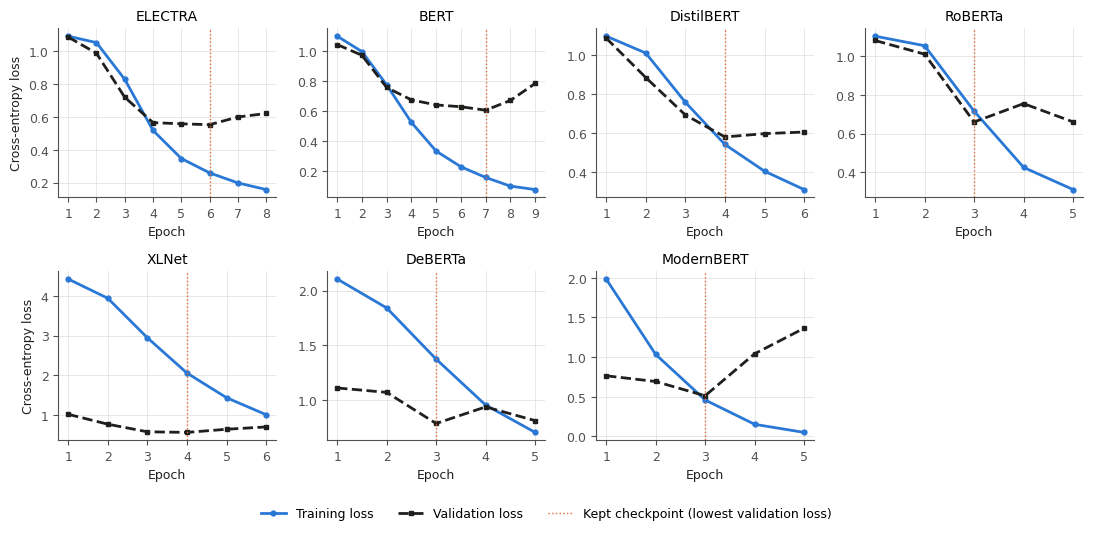

  figure saved: ft_loss_curves


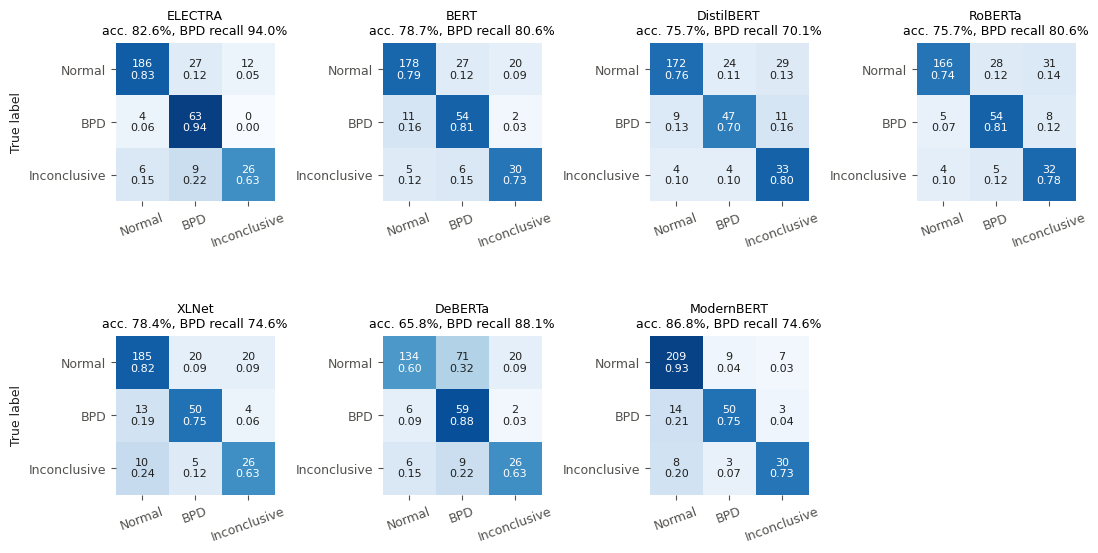

  figure saved: ft_confusion_matrices


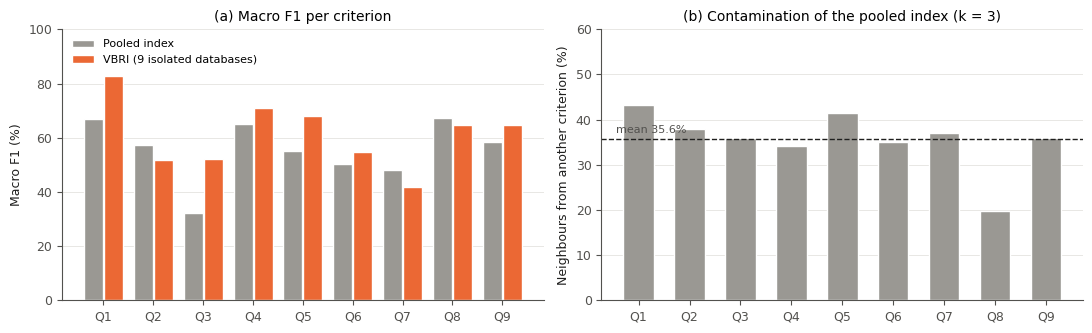

  figure saved: contamination_per_criterion


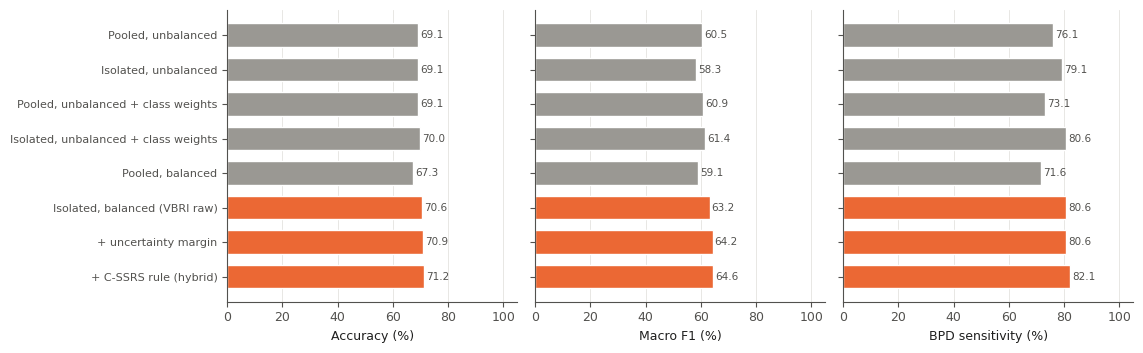

  figure saved: ablation_progression


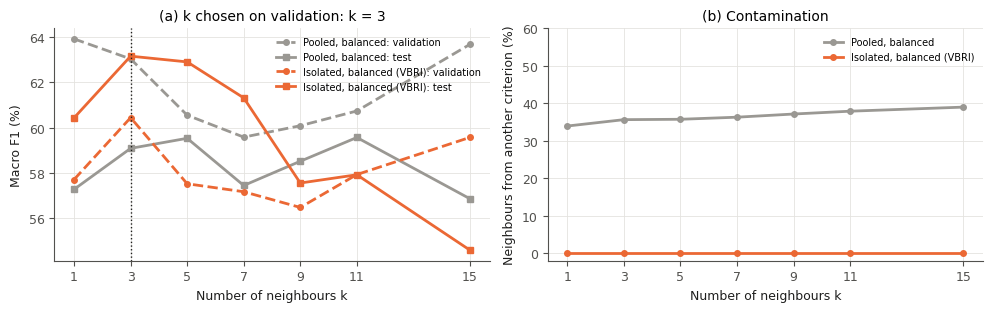

  figure saved: k_sweep


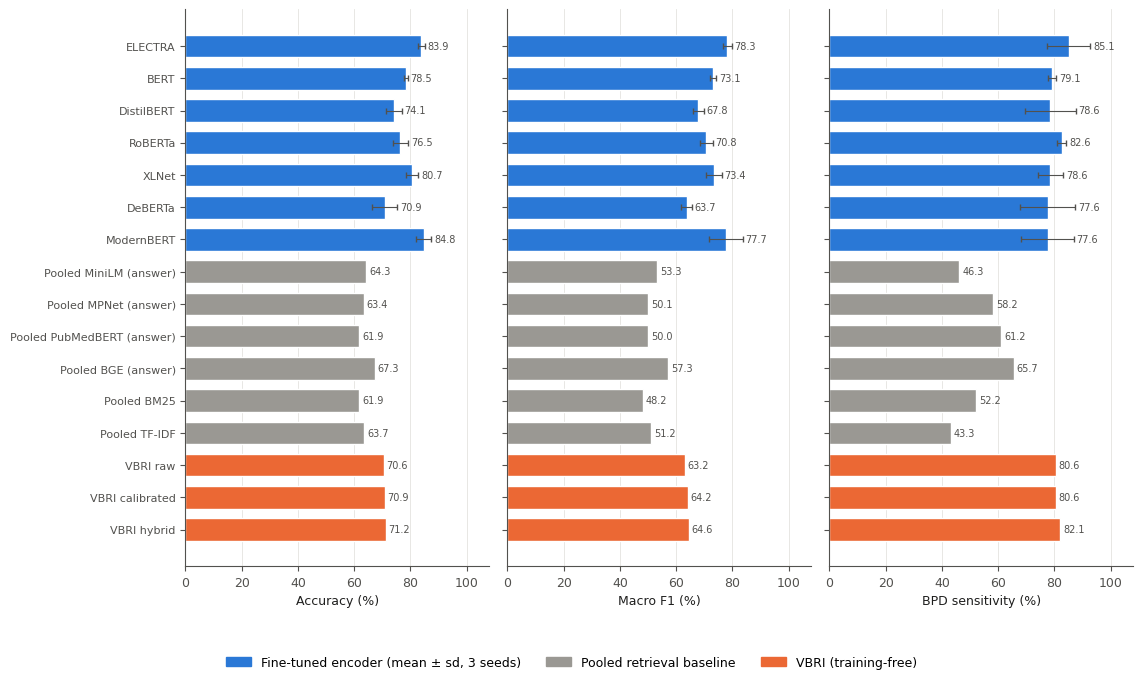

  figure saved: effectiveness_comparison


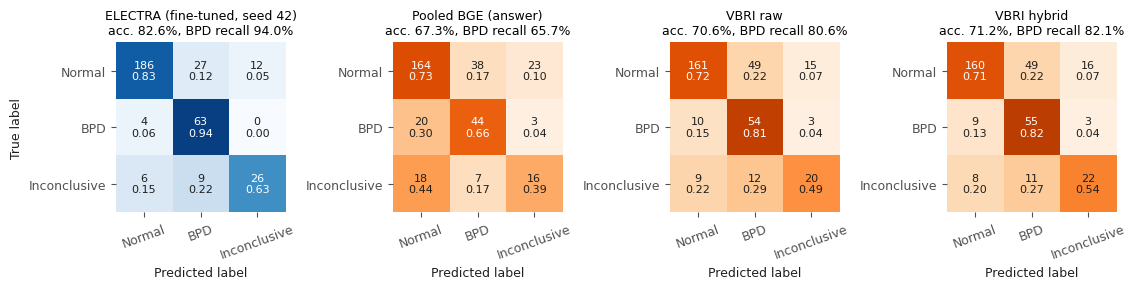

  figure saved: head_to_head_confusion


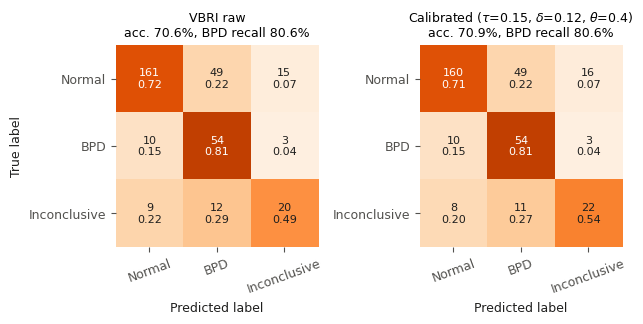

  figure saved: calibration_before_after


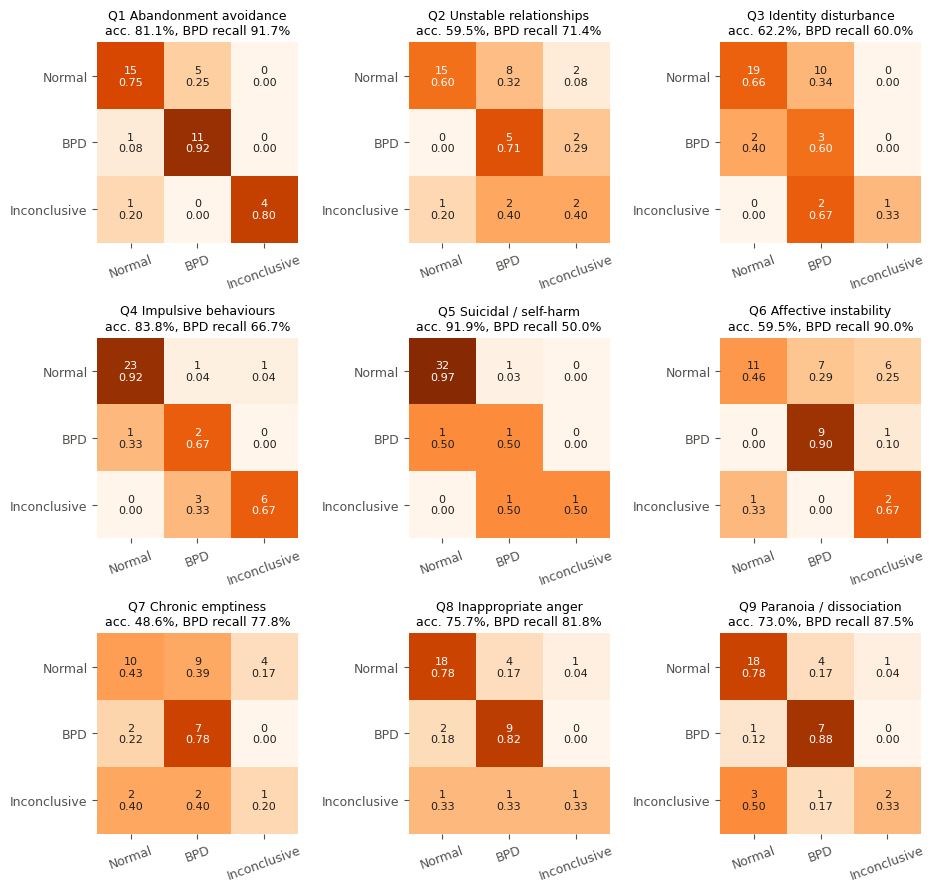

  figure saved: vdb_confusion_per_criterion


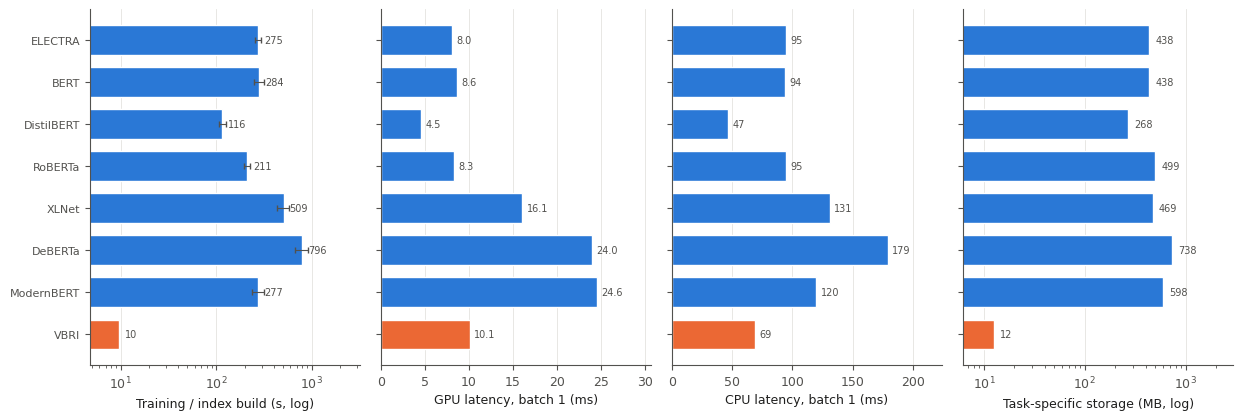

  figure saved: cost_comparison


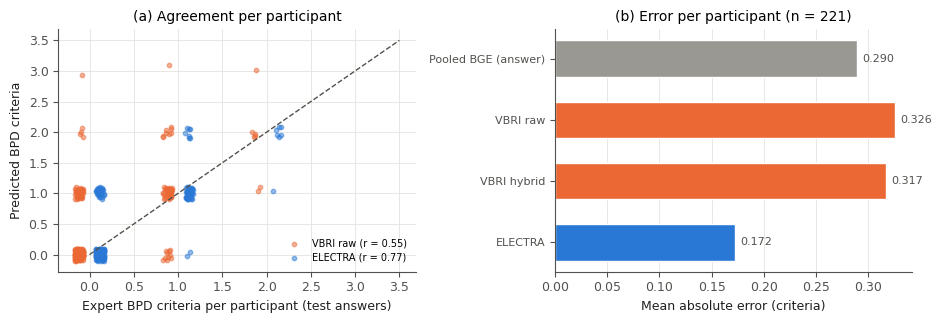

  figure saved: patient_level_agreement


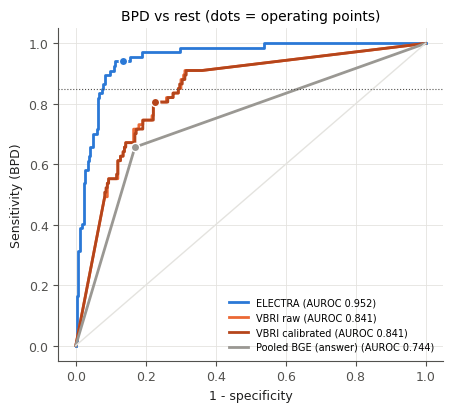

  figure saved: roc_bpd

All figures in /kaggle/working/final_baseline_run/paper_assets/figures


In [17]:
import matplotlib.ticker, matplotlib.lines, matplotlib.patches

def _ft_order(names):
    order = MODELS + ["DeBERTa-fp32"]
    return sorted(names, key=lambda n: order.index(n) if n in order else 99)

def make_result_figures():
    by = ft_by_model()
    R, A = RETR, ANALYSIS
    s0 = SEEDS[0]
    best = A["best_finetuned"]["model"] if A else None

    # ---- 1. loss curves (first seed) ----
    hist = {}
    for m in _ft_order(by):
        h = read_json(RUNS_DIR / f"seed{s0}" / m / "history.json", None)
        if h:
            hist[m] = h
    if hist:
        n = len(hist); cols = 4; rows = math.ceil(n / cols)
        fig, axes = plt.subplots(rows, cols, figsize=(11, 2.6 * rows), squeeze=False)
        for ax, (m, h) in zip(axes.flat, hist.items()):
            tr = [(e["epoch"], e["loss"]) for e in h if "loss" in e and "eval_loss" not in e and "train_runtime" not in e]
            va = [(e["epoch"], e["eval_loss"]) for e in h if "eval_loss" in e]
            ax.plot(*zip(*tr), color=C_FT, lw=2, marker="o", ms=3.5, label="Training loss") if tr else None
            ax.plot(*zip(*va), color=INK, lw=2, ls="--", marker="s", ms=3.5, label="Validation loss") if va else None
            if va:
                ax.axvline(min(va, key=lambda t: t[1])[0], color=C_VB, lw=1, ls=":")
            ax.set_title(m)
            ax.set_xlabel("Epoch")
            ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
        for ax in axes.flat[n:]:
            ax.axis("off")
        for ax in axes[:, 0]:
            ax.set_ylabel("Cross-entropy loss")
        h_, l_ = axes[0, 0].get_legend_handles_labels()
        h_.append(matplotlib.lines.Line2D([], [], color=C_VB, ls=":", lw=1)); l_.append("Kept checkpoint (lowest validation loss)")
        fig.legend(h_, l_, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.03))
        fig.tight_layout(rect=(0, 0.04, 1, 1))
        save_fig(fig, "ft_loss_curves")

    # ---- 2. fine-tuned confusion matrices (first seed) ----
    cms = {m: rs[0]["test"]["confusion"] for m, rs in ((m, [r for r in by[m] if r["seed"] == s0]) for m in _ft_order(by)) if rs}
    if cms:
        n = len(cms); cols = 4; rows = math.ceil(n / cols)
        fig, axes = plt.subplots(rows, cols, figsize=(11, 3.0 * rows), squeeze=False)
        for ax, (m, cm) in zip(axes.flat, cms.items()):
            draw_cm(ax, cm, m)
        for ax in axes.flat[n:]:
            ax.axis("off")
        for ax in axes[:, 0]:
            ax.set_ylabel("True label")
        fig.tight_layout()
        save_fig(fig, "ft_confusion_matrices")

    if R:
        pc = R["per_criterion"]
        qs = [str(q) for q in range(1, 10)]
        # ---- 3. per-criterion macro-F1 and contamination ----
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
        x = np.arange(9)
        axes[0].bar(x - 0.2, [pc[q]["pooled"]["macro_f1"] for q in qs], 0.38, color=C_BASE, label="Pooled index", edgecolor="white")
        axes[0].bar(x + 0.2, [pc[q]["vbri"]["macro_f1"] for q in qs], 0.38, color=C_VB, label="VBRI (9 isolated databases)", edgecolor="white")
        axes[0].set_ylabel("Macro F1 (%)"); axes[0].set_ylim(0, 100); axes[0].legend(fontsize=8, loc="upper left")
        axes[0].set_title("(a) Macro F1 per criterion")
        cont = [pc[q]["pooled_contamination_pct"] for q in qs]
        axes[1].bar(x, cont, 0.6, color=C_BASE, edgecolor="white")
        mc = R["rows"]["VBRI raw"]["k"]
        mean_c = float(np.mean(cont))
        axes[1].axhline(mean_c, color=INK, ls="--", lw=1)
        axes[1].text(-0.45, mean_c + 1, f"mean {mean_c:.1f}%", ha="left", va="bottom", fontsize=8, color=INK2)
        axes[1].set_ylabel("Neighbours from another criterion (%)"); axes[1].set_ylim(0, max(60, max(cont) + 10))
        axes[1].set_title(f"(b) Contamination of the pooled index (k = {mc})")
        for ax in axes:
            ax.set_xticks(x, [f"Q{q}" for q in qs]); ax.grid(axis="x", visible=False)
        fig.tight_layout()
        save_fig(fig, "contamination_per_criterion")

        # ---- 4. ablation ----
        ab = R["ablation"]
        steps = [(k, v["test"]) for k, v in ab.items()]
        steps += [("+ uncertainty margin", R["rows"]["VBRI calibrated"]["test"]), ("+ C-SSRS rule (hybrid)", R["rows"]["VBRI hybrid"]["test"])]
        fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), sharey=True)
        y = np.arange(len(steps))[::-1]
        colr = [C_VB if ("Isolated, balanced" in k or k.startswith("+")) else C_BASE for k, _ in steps]
        for ax, key, lab in zip(axes, ("accuracy", "macro_f1", "bpd_sensitivity"), ("Accuracy (%)", "Macro F1 (%)", "BPD sensitivity (%)")):
            vals = [m[key] for _, m in steps]
            ax.barh(y, vals, color=colr, height=0.68, edgecolor="white")
            for yy, v in zip(y, vals):
                ax.text(v + 0.8, yy, f"{v:.1f}", va="center", fontsize=7.5, color=INK2)
            ax.set_xlim(0, 105); ax.set_xlabel(lab); ax.grid(axis="y", visible=False)
        axes[0].set_yticks(y, [k for k, _ in steps], fontsize=8)
        fig.tight_layout()
        save_fig(fig, "ablation_progression")

        # ---- 5. k-sweep ----
        ks = R["k_sweep"]
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
        for nm, colr_ in (("Pooled, balanced", C_BASE), ("Isolated, balanced (VBRI)", C_VB)):
            kk = sorted(int(k) for k in ks[nm])
            axes[0].plot(kk, [ks[nm][str(k)]["val_macro_f1"] for k in kk], color=colr_, lw=2, ls="--", marker="o", ms=4, label=f"{nm}: validation")
            axes[0].plot(kk, [ks[nm][str(k)]["test_macro_f1"] for k in kk], color=colr_, lw=2, marker="s", ms=4, label=f"{nm}: test")
            axes[1].plot(kk, [ks[nm][str(k)]["test_contamination_pct"] for k in kk], color=colr_, lw=2, marker="o", ms=4, label=nm)
        axes[0].axvline(R["rows"]["VBRI raw"]["k"], color=INK, lw=1, ls=":")
        axes[0].set_ylabel("Macro F1 (%)"); axes[0].legend(fontsize=7)
        axes[0].set_title(f"(a) k chosen on validation: k = {R['rows']['VBRI raw']['k']}")
        axes[1].set_ylabel("Neighbours from another criterion (%)"); axes[1].set_ylim(-2, 60); axes[1].legend(fontsize=7)
        axes[1].set_title("(b) Contamination")
        for ax in axes:
            ax.set_xlabel("Number of neighbours k"); ax.set_xticks(K_GRID)
        fig.tight_layout()
        save_fig(fig, "k_sweep")

        # ---- 6. effectiveness comparison ----
        rows_ = []
        for m in _ft_order(by):
            rs = by[m]
            rows_.append((f"{m}", "ft", *[pct_stats([r["test"][k] for r in rs]) for k in ("accuracy", "macro_f1", "bpd_sensitivity")]))
        dense = [k for k, v in R["rows"].items() if v["family"] == "pooled_dense"]
        best_fmt = {}
        for k in dense:
            enc = R["rows"][k]["encoder"]
            if enc not in best_fmt or R["rows"][k]["val"]["macro_f1"] > R["rows"][best_fmt[enc]]["val"]["macro_f1"]:
                best_fmt[enc] = k
        for k in list(best_fmt.values()) + [k for k, v in R["rows"].items() if v["family"] == "lexical"]:
            rows_.append((k, "base", *[(R["rows"][k]["test"][x], 0.0) for x in ("accuracy", "macro_f1", "bpd_sensitivity")]))
        for k in ("VBRI raw", "VBRI calibrated", "VBRI hybrid"):
            rows_.append((k, "vb", *[(R["rows"][k]["test"][x], 0.0) for x in ("accuracy", "macro_f1", "bpd_sensitivity")]))
        colmap = {"ft": C_FT, "base": C_BASE, "vb": C_VB}
        fig, axes = plt.subplots(1, 3, figsize=(11.5, 0.33 * len(rows_) + 1.3), sharey=True)
        y = np.arange(len(rows_))[::-1]
        for j, (ax, lab) in enumerate(zip(axes, ("Accuracy (%)", "Macro F1 (%)", "BPD sensitivity (%)"))):
            mu = [r[2 + j][0] for r in rows_]; sd = [r[2 + j][1] for r in rows_]
            ax.barh(y, mu, color=[colmap[r[1]] for r in rows_], height=0.7, edgecolor="white")
            eb = [i for i, v in enumerate(sd) if v > 0]
            if eb:
                ax.errorbar([mu[i] for i in eb], [y[i] for i in eb], xerr=[sd[i] for i in eb], fmt="none",
                            ecolor=INK2, elinewidth=0.8, capsize=2)
            for yy, v, s_ in zip(y, mu, sd):
                ax.text(v + s_ + 1, yy, f"{v:.1f}", va="center", fontsize=7, color=INK2)
            ax.set_xlim(0, 108); ax.set_xlabel(lab); ax.grid(axis="y", visible=False)
        axes[0].set_yticks(y, [r[0] for r in rows_], fontsize=8)
        handles = [matplotlib.patches.Patch(color=c) for c in (C_FT, C_BASE, C_VB)]
        fig.legend(handles, [f"Fine-tuned encoder (mean ± sd, {len(SEEDS)} seed{'s' if len(SEEDS) > 1 else ''})", "Pooled retrieval baseline", "VBRI (training-free)"],
                   loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
        fig.tight_layout(rect=(0, 0.05, 1, 1))
        save_fig(fig, "effectiveness_comparison")

        # ---- 7. head-to-head confusion ----
        panels = []
        if best and any(r["seed"] == s0 for r in by.get(best, [])):
            panels.append((f"{best} (fine-tuned, seed {s0})", [r for r in by[best] if r["seed"] == s0][0]["test"]["confusion"], "Blues"))
        pooled_name = "Pooled BGE (answer)" if "Pooled BGE (answer)" in R["rows"] else f"Pooled {VBRI_ENCODER} (answer)"
        for nm in (pooled_name, "VBRI raw", "VBRI hybrid"):
            panels.append((nm, R["rows"][nm]["test"]["confusion"], "Oranges"))
        fig, axes = plt.subplots(1, len(panels), figsize=(2.85 * len(panels), 3.2), squeeze=False)
        for ax, (t, cm, cmap) in zip(axes[0], panels):
            draw_cm(ax, cm, t, cmap)
            ax.set_xlabel("Predicted label")
        axes[0, 0].set_ylabel("True label")
        fig.tight_layout()
        save_fig(fig, "head_to_head_confusion")

        # ---- 8. calibration before / after ----
        fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.2))
        c = R["calibration"]["chosen"]
        draw_cm(axes[0], R["rows"]["VBRI raw"]["test"]["confusion"], "VBRI raw", "Oranges")
        draw_cm(axes[1], R["rows"]["VBRI calibrated"]["test"]["confusion"], rf"Calibrated ($\tau$={c['tau']}, $\delta$={c['delta']}, $\theta$={c['theta']})", "Oranges")
        axes[0].set_ylabel("True label")
        for ax in axes:
            ax.set_xlabel("Predicted label")
        fig.tight_layout()
        save_fig(fig, "calibration_before_after")

        # ---- 9. per-criterion confusion matrices of VBRI ----
        fig, axes = plt.subplots(3, 3, figsize=(9.5, 9))
        for ax, q in zip(axes.flat, qs):
            draw_cm(ax, pc[q]["vbri"]["confusion"], f"Q{q} {DSM5[int(q)]}", "Oranges")
        fig.tight_layout()
        save_fig(fig, "vdb_confusion_per_criterion")

    # ---- 10. cost comparison ----
    inf = {r["model"]: r for r in (read_json(WORK_DIR / "inference_benchmark.json", []) or [])}
    vt = VBRI_TIME
    if by and vt:
        names = [m for m in _ft_order(by) if not m.endswith("-fp32")]
        tr = [pct_stats([r["timing"]["effective_s"] for r in by[m]]) for m in names]
        stor = [next((r.get("weights_mb") for r in by[m] if r.get("weights_mb")), None) for m in names]
        g1 = [inf.get(m, {}).get("gpu_bs1_median_ms", float("nan")) for m in names]
        c1 = [inf.get(m, {}).get("cpu_bs1_median_ms", float("nan")) for m in names]
        names.append("VBRI"); tr.append((vt["index_build_s_median"], 0.0)); stor.append(vt["index_mb"])
        g1.append(vt.get("gpu_bs1_total_ms_median", float("nan"))); c1.append(vt.get("cpu_bs1_total_ms_median", float("nan")))
        cols = [C_FT] * (len(names) - 1) + [C_VB]
        fig, axes = plt.subplots(1, 4, figsize=(12.5, 0.36 * len(names) + 1.4), sharey=True)
        y = np.arange(len(names))[::-1]
        specs = [([t[0] for t in tr], [t[1] for t in tr], "Training / index build (s, log)", True, "{:.0f}"),
                 (g1, None, "GPU latency, batch 1 (ms)", False, "{:.1f}"),
                 (c1, None, "CPU latency, batch 1 (ms)", False, "{:.0f}"),
                 ([s if s else float("nan") for s in stor], None, "Task-specific storage (MB, log)", True, "{:.0f}")]
        for ax, (vals, err, lab, lg, fmt) in zip(axes, specs):
            ax.barh(y, vals, color=cols, height=0.7, edgecolor="white")
            if err:
                eb = [i for i, e in enumerate(err) if e and e > 0]
                if eb:
                    ax.errorbar([vals[i] for i in eb], [y[i] for i in eb], xerr=[err[i] for i in eb], fmt="none",
                                ecolor=INK2, elinewidth=0.8, capsize=2)
            if not [v for v in vals if v == v]:
                ax.text(0.5, 0.5, "not measured\n(no GPU in this run)", transform=ax.transAxes, ha="center", va="center", fontsize=8, color=INK2)
            if lg:
                ax.set_xscale("log")
            for yy, v in zip(y, vals):
                if v == v:
                    ax.text(v * (1.15 if lg else 1.0) + (0 if lg else max(x for x in vals if x == x) * 0.02), yy, fmt.format(v),
                            va="center", fontsize=7, color=INK2)
            ax.set_xlabel(lab); ax.grid(axis="y", visible=False)
            finite = [v for v in vals if v == v]
            if finite:
                ax.set_xlim((min(finite) / 2, max(finite) * 4) if lg else (0, max(finite) * 1.25))
        axes[0].set_yticks(y, names, fontsize=8)
        fig.tight_layout()
        save_fig(fig, "cost_comparison")

    if A:
        # ---- 11. participant level ----
        P = A["participant"]
        fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
        rng = np.random.default_rng(0)
        tc = np.array(P["true_counts"])
        for nm, col, off in (("VBRI raw", C_VB, -0.12), (best, C_FT, 0.12)):
            if nm in P["models"]:
                pcnt = np.array(P["models"][nm]["counts"])
                axes[0].scatter(tc + off + rng.uniform(-0.05, 0.05, len(tc)), pcnt + rng.uniform(-0.1, 0.1, len(tc)), s=10, alpha=0.5,
                                color=col, label=f"{nm} (r = {P['models'][nm]['pearson_r']:.2f})")
        mx = max(tc.max(), max(max(v["counts"]) for v in P["models"].values())) + 0.5
        axes[0].plot([0, mx], [0, mx], color=INK2, ls="--", lw=1)
        axes[0].set_xlabel("Expert BPD criteria per participant (test answers)"); axes[0].set_ylabel("Predicted BPD criteria")
        axes[0].legend(fontsize=7); axes[0].set_title("(a) Agreement per participant")
        nms = list(P["models"])
        maes = [P["models"][n]["mae"] for n in nms]
        axes[1].barh(np.arange(len(nms))[::-1], maes, color=[C_FT if n == best else (C_VB if n.startswith("VBRI") else C_BASE) for n in nms],
                     height=0.6, edgecolor="white")
        for yy, v in zip(np.arange(len(nms))[::-1], maes):
            axes[1].text(v + 0.005, yy, f"{v:.3f}", va="center", fontsize=8, color=INK2)
        axes[1].set_yticks(np.arange(len(nms))[::-1], nms, fontsize=8); axes[1].set_xlabel("Mean absolute error (criteria)")
        axes[1].set_title(f"(b) Error per participant (n = {P['n_participants']})"); axes[1].grid(axis="y", visible=False)
        fig.tight_layout()
        save_fig(fig, "patient_level_agreement")

        # ---- 12. ROC, BPD vs rest ----
        fig, ax = plt.subplots(figsize=(4.6, 4.2))
        colr = {best: C_FT, "VBRI raw": C_VB, "VBRI calibrated": "#b5451b", "Pooled BGE (answer)": C_BASE}
        for nm, d in A["roc"].items():
            ax.plot(d["fpr"], d["tpr"], color=colr.get(nm, INK2), lw=2, label=f"{nm} (AUROC {d['auroc']:.3f})")
            op = d["operating_point"]
            ax.plot(1 - op["spec"] / 100, op["sens"] / 100, marker="o", ms=6, color=colr.get(nm, INK2), mec="white")
        ax.plot([0, 1], [0, 1], color=GRID, lw=1)
        ax.axhline(0.85, color=INK2, lw=0.8, ls=":")
        ax.set_xlabel("1 - specificity"); ax.set_ylabel("Sensitivity (BPD)")
        ax.legend(fontsize=7, loc="lower right"); ax.set_title("BPD vs rest (dots = operating points)")
        fig.tight_layout()
        save_fig(fig, "roc_bpd")

if RUN_FIGURES:
    make_result_figures()
    print("\nAll figures in", FIG_DIR)

## 16. LaTeX tables and `numbers.json` (in `paper_assets/tables`)

In [18]:
def tex_escape(s):
    rep = {"\\": r"\textbackslash{}", "&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_", "{": r"\{", "}": r"\}",
           "~": r"\textasciitilde{}", "^": r"\textasciicircum{}"}
    return "".join(rep.get(ch, ch) for ch in str(s))

def _ms(vals, d=2):
    m, s = pct_stats(vals)
    if m != m:
        return "--"
    return f"{m:.{d}f}" if len(vals) < 2 else f"{m:.{d}f} $\\pm$ {s:.{d}f}"

def _w(name, lines):
    (TAB_DIR / f"{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("  table saved:", name)

def make_tables():
    by = ft_by_model()
    R, A, vt = RETR, ANALYSIS, VBRI_TIME
    inf = {r["model"]: r for r in (read_json(WORK_DIR / "inference_benchmark.json", []) or [])}
    NUM = {"code_version": CODE_VERSION, "seeds": SEEDS, "gpu": GPU_NAME, "env": ENV, "dataset": DATASET_REPORT}

    # ---- fine-tuned encoders (mean +- sd over seeds) ----
    L = [r"\begin{tabular}{@{}lccccccccc@{}}", r"\toprule",
         r"\textbf{Model} & \textbf{Params} & \textbf{Prec.} & \textbf{Train time (s)} & \textbf{Epochs} & \textbf{Accuracy} & \textbf{Weighted F1} & \textbf{Macro F1} & \textbf{BPD F1} & \textbf{BPD Sens.} \\",
         r"\midrule"]
    NUM["finetuned"] = {}
    for m in _ft_order(by):
        rs = by[m]
        g = lambda f: [f(r) for r in rs]
        L.append(f"{m} & {rs[0]['params_m']:.0f}M & {rs[0]['precision']} & {_ms(g(lambda r: r['timing']['effective_s']), 0)} & "
                 f"{_ms(g(lambda r: r['epochs_run']), 1)} & {_ms(g(lambda r: r['test']['accuracy']))} & {_ms(g(lambda r: r['test']['weighted_f1']))} & "
                 f"{_ms(g(lambda r: r['test']['macro_f1']))} & {_ms(g(lambda r: r['test']['bpd_f1']))} & {_ms(g(lambda r: r['test']['bpd_sensitivity']))} \\\\")
        NUM["finetuned"][m] = {k: pct_stats(g(f)) for k, f in {
            "train_effective_s": lambda r: r["timing"]["effective_s"], "train_gross_s": lambda r: r["timing"]["gross_s"],
            "train_wasted_s": lambda r: r["timing"]["wasted_s"], "epochs": lambda r: r["epochs_run"],
            "accuracy": lambda r: r["test"]["accuracy"], "macro_f1": lambda r: r["test"]["macro_f1"],
            "weighted_f1": lambda r: r["test"]["weighted_f1"], "bpd_f1": lambda r: r["test"]["bpd_f1"],
            "bpd_sensitivity": lambda r: r["test"]["bpd_sensitivity"], "specificity": lambda r: r["test"]["bin_specificity"],
            "auroc": lambda r: r.get("auroc_bpd", float("nan")), "spec_at_sens85": lambda r: r.get("spec_at_sens85", float("nan")),
            "val_macro_f1": lambda r: r["val"]["macro_f1"]}.items()}
        NUM["finetuned"][m].update({"n_seeds": len(rs), "params_m": rs[0]["params_m"], "precision": rs[0]["precision"],
                                    "collapsed_any": any(r["collapsed"] for r in rs), "n_sessions": [r["timing"]["n_sessions"] for r in rs]})
    L += [r"\bottomrule", r"\end{tabular}"]
    _w("tab_encoder_results", L)

    if R:
        # ---- master table ----
        L = [r"\begin{tabular}{@{}llccccccc@{}}", r"\toprule",
             r"\textbf{Paradigm} & \textbf{Model} & \textbf{Trainable} & \textbf{k} & \textbf{Contam.} & \textbf{Accuracy} & \textbf{Macro F1} & \textbf{BPD Sens.} & \textbf{BPD F1} \\",
             r"\midrule"]
        for m in _ft_order(by):
            rs = by[m]
            L.append(f"Fine-tuned & {m} & {rs[0]['params_m']:.0f}M & -- & N/A & {_ms([r['test']['accuracy'] for r in rs])} & "
                     f"{_ms([r['test']['macro_f1'] for r in rs])} & {_ms([r['test']['bpd_sensitivity'] for r in rs])} & {_ms([r['test']['bpd_f1'] for r in rs])} \\\\")
        L.append(r"\midrule")
        fam_lab = {"pooled_dense": "Pooled dense", "lexical": "Pooled lexical", "vbri": r"\textbf{VBRI (ours)}"}
        for fam in ("pooled_dense", "lexical", "vbri"):
            for nm, v in R["rows"].items():
                if v["family"] != fam:
                    continue
                t = v["test"]
                L.append(f"{fam_lab[fam]} & {tex_escape(nm)} & 0 & {v['k']} & {v.get('contamination_pct', 0.0) if fam != 'vbri' else 0.0:.1f} & "
                         f"{t['accuracy']:.2f} & {t['macro_f1']:.2f} & {t['bpd_sensitivity']:.2f} & {t['bpd_f1']:.2f} \\\\")
            L.append(r"\midrule" if fam != "vbri" else r"\bottomrule")
        L.append(r"\end{tabular}")
        _w("tab_master", L)
        NUM["retrieval_rows"] = {k: {"k": v["k"], "test": {x: v["test"][x] for x in ("accuracy", "macro_f1", "weighted_f1", "bpd_sensitivity", "bpd_f1", "bin_specificity", "bin_ppv", "bin_npv", "inconclusive_recall")},
                                     "contamination_pct": v.get("contamination_pct"), "test_k5_accuracy": v.get("test_k5", {}).get("accuracy")}
                                 for k, v in R["rows"].items()}
        NUM["calibration"] = R["calibration"]["chosen"]
        NUM["cssrs"] = R["cssrs"]
        NUM["reproduction_check"] = R.get("reproduction_check")
        NUM["per_criterion_test"] = R.get("per_criterion_test")
        NUM["ablation_mcnemar"] = R.get("ablation_mcnemar")

        # ---- ablation ----
        L = [r"\begin{tabular}{@{}lcccccc@{}}", r"\toprule",
             r"\textbf{Configuration} & \textbf{Vectors} & \textbf{Isolation} & \textbf{Balance} & \textbf{Accuracy} & \textbf{Macro F1} & \textbf{BPD Sens.} \\", r"\midrule"]
        for nm, v in R["ablation"].items():
            bal = r"\checkmark" if v["train"] == "bal" else ("weights" if v["class_weights"] else "--")
            iso_mark = r"\checkmark" if v["isolated"] else "--"
            L.append(f"{tex_escape(nm)} & {v['n_vectors']:,} & {iso_mark} & {bal} & "
                     f"{v['test']['accuracy']:.2f} & {v['test']['macro_f1']:.2f} & {v['test']['bpd_sensitivity']:.2f} \\\\")
        c = R["calibration"]["chosen"]
        for nm, lab in (("VBRI calibrated", f"\\quad + uncertainty margin ($\\tau$={c['tau']}, $\\delta$={c['delta']}, $\\theta$={c['theta']})"),
                        ("VBRI hybrid", r"\quad + C-SSRS rule (hybrid)")):
            t = R["rows"][nm]["test"]
            L.append(f"{lab} & 4,050 & \\checkmark & \\checkmark & {t['accuracy']:.2f} & {t['macro_f1']:.2f} & {t['bpd_sensitivity']:.2f} \\\\")
        L += [r"\bottomrule", r"\end{tabular}"]
        _w("tab_ablation", L)
        NUM["ablation"] = {k: {**{x: v["test"][x] for x in ("accuracy", "macro_f1", "bpd_sensitivity")}, "contamination_pct": v["contamination_pct"]}
                           for k, v in R["ablation"].items()}

        # ---- per criterion ----
        L = [r"\begin{tabular}{@{}clcccccccc@{}}", r"\toprule",
             r"\textbf{Q} & \textbf{Criterion} & \textbf{N} & \textbf{Contam.} & \textbf{Pooled acc.} & \textbf{VBRI acc.} & \textbf{$\Delta$} & \textbf{Pooled BPD F1} & \textbf{VBRI BPD F1} & \textbf{$\Delta$} \\", r"\midrule"]
        for q in range(1, 10):
            d = R["per_criterion"][str(q)]
            pa, va_, pf, vf = d["pooled"]["accuracy"], d["vbri"]["accuracy"], d["pooled"]["bpd_f1"], d["vbri"]["bpd_f1"]
            L.append(f"Q{q} & {DSM5[q]} & {d['n']} & {d['pooled_contamination_pct']:.1f} & {pa:.1f} & {va_:.1f} & {va_ - pa:+.1f} & {pf:.1f} & {vf:.1f} & {vf - pf:+.1f} \\\\")
        L += [r"\bottomrule", r"\end{tabular}"]
        _w("tab_per_criterion", L)
        NUM["per_criterion"] = R["per_criterion"]

    # ---- cost ----
    if by and vt:
        L = [r"\begin{tabular}{@{}lcccccc@{}}", r"\toprule",
             r"\textbf{Model} & \textbf{Gradient updates} & \textbf{Train / index (s)} & \textbf{GPU bs 1 (ms)} & \textbf{GPU bs 32 (ms/ans.)} & \textbf{CPU bs 1 (ms)} & \textbf{Storage (MB)} \\", r"\midrule"]
        NUM["cost"] = {}
        for m in _ft_order(by):
            if m.endswith("-fp32"):
                continue
            rs = by[m]; i = inf.get(m, {})
            wmb = next((r.get("weights_mb") for r in rs if r.get("weights_mb")), None)
            f = lambda k: f"{i[k]:.2f}" if k in i else "--"
            L.append(f"{m} & Yes & {_ms([r['timing']['effective_s'] for r in rs], 0)} & {f('gpu_bs1_median_ms')} & {f('gpu_bs32_ms_per_answer')} & {f('cpu_bs1_median_ms')} & {wmb if wmb else '--'} \\\\")
            NUM["cost"][m] = {"train_effective_s": pct_stats([r["timing"]["effective_s"] for r in rs]), "weights_mb": wmb, **{k: i.get(k) for k in ("gpu_bs1_median_ms", "gpu_bs32_ms_per_answer", "cpu_bs1_median_ms")}}
        g = lambda k: f"{vt[k]:.2f}" if k in vt else "--"
        L.append(r"\midrule")
        L.append(f"\\textbf{{VBRI}} & \\textbf{{No}} & {vt['index_build_s_median']:.1f} & {g('gpu_bs1_total_ms_median')} & {g('gpu_bs32_ms_per_answer')} & {g('cpu_bs1_total_ms_median')} & {vt['index_mb']:.1f} \\\\")
        L += [r"\bottomrule", r"\end{tabular}"]
        _w("tab_cost", L)
        NUM["vbri_timing"] = vt

    # ---- screening view + statistics ----
    if A and R:
        best = A["best_finetuned"]["model"]
        L = [r"\begin{tabular}{@{}lcccccc@{}}", r"\toprule",
             r"\textbf{Model} & \textbf{Accuracy} & \textbf{Sensitivity} & \textbf{Specificity} & \textbf{PPV} & \textbf{NPV} & \textbf{AUROC} \\", r"\midrule"]
        if best in by:
            rs = by[best]
            L.append(f"{best} (fine-tuned, {len(rs)} seeds) & {_ms([r['test']['bin_accuracy'] for r in rs])} & {_ms([r['test']['bin_sensitivity'] for r in rs])} & "
                     f"{_ms([r['test']['bin_specificity'] for r in rs])} & {_ms([r['test']['bin_ppv'] for r in rs])} & {_ms([r['test']['bin_npv'] for r in rs])} & "
                     f"{_ms([r.get('auroc_bpd', float('nan')) for r in rs], 3)} \\\\")
        for nm in ("VBRI raw", "VBRI calibrated", "VBRI hybrid", "Pooled BGE (answer)"):
            if nm in R["rows"]:
                t = R["rows"][nm]["test"]
                au = A["roc"].get(nm, {}).get("auroc")
                L.append(f"{nm} & {t['bin_accuracy']:.2f} & {t['bin_sensitivity']:.2f} & {t['bin_specificity']:.2f} & {t['bin_ppv']:.2f} & {t['bin_npv']:.2f} & {au:.3f} \\\\"
                         if au is not None else f"{nm} & {t['bin_accuracy']:.2f} & {t['bin_sensitivity']:.2f} & {t['bin_specificity']:.2f} & {t['bin_ppv']:.2f} & {t['bin_npv']:.2f} & -- \\\\")
        L += [r"\bottomrule", r"\end{tabular}"]
        _w("tab_screening", L)

        L = [r"\begin{tabular}{@{}lcccc@{}}", r"\toprule",
             r"\textbf{Model / difference} & \textbf{Accuracy} & \textbf{Macro F1} & \textbf{BPD Sens.} & \textbf{Specificity} \\", r"\midrule"]
        fmt = lambda v: f"{v['point']:.2f} [{v['ci95'][0]:.2f}, {v['ci95'][1]:.2f}]"
        for nm, d in A["bootstrap"]["ci"].items():
            L.append(f"{tex_escape(nm)} & " + " & ".join(fmt(d[m]) for m in ("accuracy", "macro_f1", "bpd_sensitivity", "bin_specificity")) + r" \\")
        L.append(r"\midrule")
        for nm, d in A["bootstrap"]["differences"].items():
            L.append(f"{tex_escape(nm)} & " + " & ".join(fmt(d[m]) for m in ("accuracy", "macro_f1", "bpd_sensitivity", "bin_specificity")) + r" \\")
        L += [r"\bottomrule", r"\end{tabular}"]
        _w("tab_bootstrap", L)

        L = [r"\begin{tabular}{@{}p{2.2cm}p{5.2cm}p{1.6cm}p{2.2cm}p{4.4cm}@{}}", r"\toprule",
             r"\textbf{Case} & \textbf{Answer (excerpt)} & \textbf{True} & \textbf{Predictions} & \textbf{Retrieved neighbours (VBRI)} \\", r"\midrule"]
        for v in A["vignettes"]:
            nb = "; ".join(f"{n['label']} ({n['sim']:.2f})" for n in v["vbri_neighbours"])
            L.append(f"{tex_escape(v['case'])} (Q{v['question']}) & ``{tex_escape(v['answer'][:150])}\\ldots'' & {v['true']} & "
                     f"Pooled: {v['pooled_pred']} ({v['pooled_contamination_pct']:.0f}\\% contam.)\\newline VBRI: {v['vbri_raw_pred']}\\newline Calibrated: {v['vbri_calibrated_pred']} & {tex_escape(nb)} \\\\")
        L += [r"\bottomrule", r"\end{tabular}"]
        _w("tab_vignettes", L)
        NUM["analysis"] = {k: v for k, v in A.items() if k not in ("roc", "participant")}
        NUM["roc"] = {k: {"auroc": v["auroc"], "spec_at_sens85": v["spec_at_sens85"], "operating_point": v["operating_point"]} for k, v in A["roc"].items()}
        NUM["participant"] = {k: v for k, v in A["participant"].items() if k not in ("true_counts",)}
        for nm in NUM["participant"]["models"]:
            NUM["participant"]["models"][nm] = {x: NUM["participant"]["models"][nm][x] for x in ("mae", "pearson_r")}
    NUM["data"] = read_json(PAPER_DIR / "data_stats.json", None)
    atomic_write_json(PAPER_DIR / "numbers.json", NUM)
    print("numbers.json written")

if RUN_TABLES:
    make_tables()

  table saved: tab_encoder_results
  table saved: tab_master
  table saved: tab_ablation
  table saved: tab_per_criterion
  table saved: tab_cost
  table saved: tab_screening
  table saved: tab_bootstrap
  table saved: tab_vignettes
numbers.json written


## 17. Export
Zip on the Kaggle disk, and the same bundle (PDF figures, tables, results; no weights, no PNG, no embeddings) printed below for the VS Code remote kernel.

In [19]:
def _skip(p):
    parts = p.parts
    return (p.is_dir() or "final_model" in parts or "smoke" in parts or "emb" in parts
            or any(x.startswith("checkpoint-") for x in parts) or p.name.endswith(".tmp"))

def export_results():
    # 1) full zip (Kaggle: download it from the output panel; Windows: it sits next to the work folder)
    zpath = WORK_DIR.parent / "final_baseline_run_results.zip"
    n = 0
    with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(WORK_DIR.rglob("*")):
            if not _skip(p):
                z.write(p, p.relative_to(WORK_DIR)); n += 1
    print(f"Wrote {zpath} ({n} files, {zpath.stat().st_size / 1e6:.1f} MB).")
    # 2) the same content (PDF figures, no PNG) printed into this notebook, for a VS Code remote kernel.
    #    Save the notebook locally, then run:  python experiments/publication_notebook/extract_bundle.py
    if EMBED_BUNDLE_IN_NOTEBOOK:
        buf = io.BytesIO()
        with zipfile.ZipFile(buf, "w", zipfile.ZIP_DEFLATED) as z:
            for p in sorted(WORK_DIR.rglob("*")):
                if not _skip(p) and p.suffix != ".png":
                    z.write(p, p.relative_to(WORK_DIR))
        raw = buf.getvalue()
        data = base64.b64encode(raw).decode("ascii")
        print(f"BPD_BUNDLE_BEGIN sha256={hashlib.sha256(raw).hexdigest()} bytes={len(raw)}")
        for i in range(0, len(data), 2000):
            print(data[i:i + 2000])
        print("BPD_BUNDLE_END")
        print(f"\nBundle printed ({len(raw) / 1e6:.2f} MB). Now SAVE this notebook in VS Code and run extract_bundle.py locally.")

def copy_to_paper():
    """Windows profile: copy final figures (PDF) and tables straight into the paper folder."""
    if PAPER_REPO_DIR is None or not Path(PAPER_REPO_DIR).exists():
        print("Paper folder not found (set BPD_PAPER_DIR); figures and tables stay in", PAPER_DIR)
        return
    dst_f, dst_t = Path(PAPER_REPO_DIR) / "figures" / "generated", Path(PAPER_REPO_DIR) / "tables"
    dst_f.mkdir(parents=True, exist_ok=True); dst_t.mkdir(parents=True, exist_ok=True)
    nf = nt = 0
    for p in sorted(FIG_DIR.glob("*.pdf")):
        shutil.copy2(p, dst_f / p.name); nf += 1
    for p in sorted(TAB_DIR.glob("*.tex")):
        shutil.copy2(p, dst_t / p.name); nt += 1
    for extra in ("numbers.json", "analysis.json", "data_stats.json"):
        if (PAPER_DIR / extra).exists():
            shutil.copy2(PAPER_DIR / extra, dst_t / extra)
    print(f"Copied {nf} figures to {dst_f} and {nt} tables (+ numbers.json) to {dst_t}")

if RUN_EXPORT:
    if TEST_MODE and COPY_TO_PAPER:
        print("TEST MODE: not copying test figures into the paper folder.")
    elif COPY_TO_PAPER:
        copy_to_paper()
    export_results()

Wrote /kaggle/working/final_baseline_run_results.zip (167 files, 3.3 MB).
BPD_BUNDLE_BEGIN sha256=0f0b3e2a53a5823fcf230a0be940984b23db8a672739a1724d32eccde8637609 bytes=480958
...
BPD_BUNDLE_END

Bundle printed (0.48 MB). Now SAVE this notebook in VS Code and run extract_bundle.py locally.
